In [2]:
import pandas as pd
import math
import os
import json
import seaborn as sns
import matplotlib.pyplot as plt
#print(os.getcwd())

# PanACoTA results

## Create figures for general panenome statistics

In [2]:
# Import the summary dataframe for all gene families
pan_sum_df = pd.read_csv("C:\\Users\\NOW019\\OneDrive - CSIRO\\Documents\\Papers\\Pangenomics_Microbispora\\PanACoTA_analyses\\PanGenome-MICB.All.prt-clust-0.8-mode1-th8.lst.summary.txt")

In [3]:
# Identify core genome and gene families unique to single strain
# The difference between nb_mono and sum_quali is because sum_quali also includes members with multiple copies
print(len(pan_sum_df))
print(len(pan_sum_df[pan_sum_df["nb_members"] == 1]))
print(pan_sum_df["nb_mono"].max())
print(len(pan_sum_df[pan_sum_df["nb_mono"] == 40]))
print(pan_sum_df["sum_quali"].max())
print(len(pan_sum_df[pan_sum_df["sum_quali"] == 40]))

51078
30002
40
1730
40
1776


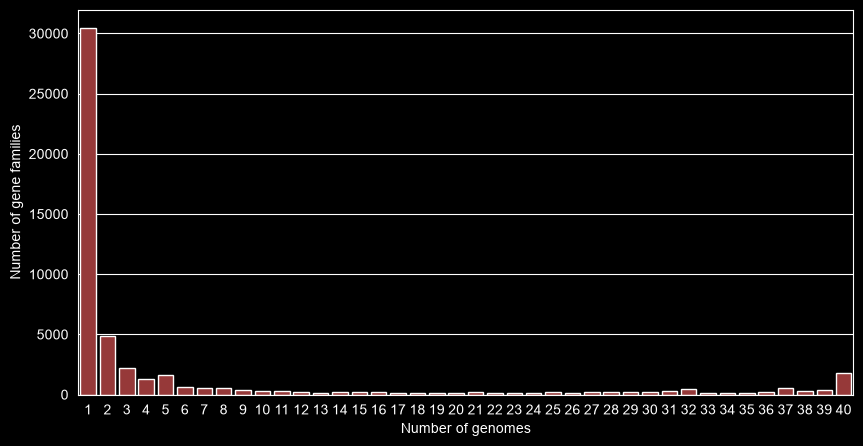

In [4]:
# Count the number of gene families conserved in x number of genomes
# According to PanACoTA documentation
# sum_quali: sum of corresponding qualitative matrix line (equal to the number of different genomes in the family)
# NOTE that this includes gene genomes with multiple copies of a gene family
conserved_gene_family_count = pan_sum_df["sum_quali"].value_counts().to_frame()
fig1, ax1 = plt.subplots(figsize=(10,5))
ax1.set(xlabel="Number of genomes", ylabel="Number of gene families")
sns.barplot(data=conserved_gene_family_count, ax=ax1, y="count", x=conserved_gene_family_count.index, color="brown")
#plt.savefig("PanACoTA_conserved_gene_family_count.png", bbox_inches='tight', dpi=600)
plt.show()

In [5]:
# Count the number of gene families added by each genome
# Could use individual protein files, but would need to cross-reference which ones are shared with another genome
pan_quali_df = pd.read_csv("PanGenome-MICB.All.prt-clust-0.8-mode1-th8.lst.quali.clean.txt")
pan_quali_df.set_index('fam_num', inplace=True)

# Use pangenome matrix to count 1's in row, write to new df, then drop those already counted and count those added by next genome
open_close_dict = {}
for i in pan_quali_df.index:
    row_data = pan_quali_df.loc[i]
    columns_with_one = row_data[row_data == 1].index.tolist()
    open_close_dict.update({i : pan_quali_df.loc[i].sum()})
    pan_quali_df.drop(columns=columns_with_one, inplace=True)

open_close_df = pd.DataFrame.from_dict(open_close_dict, orient='index')

#Check the sum adds up to expected 51,078
open_close_df.sum()

0    51078
dtype: int64

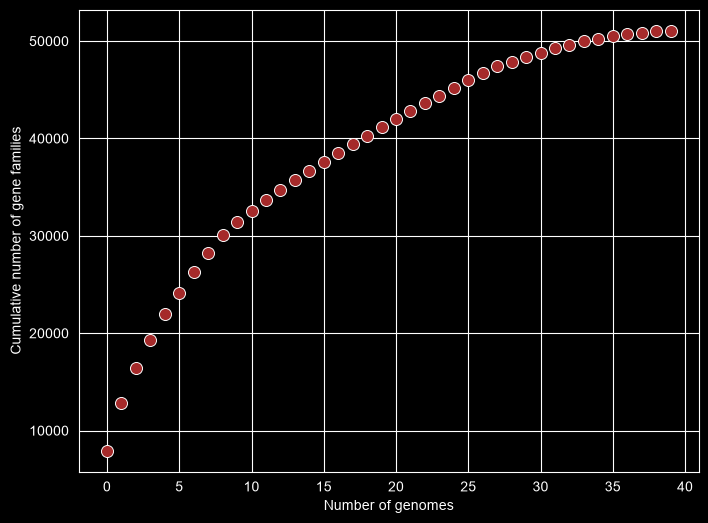

In [6]:
# Make a copy of dataframe, sort values and make numerical index
open_close_df_cp = open_close_df.copy()
open_close_df_cp.sort_values(0, ascending=False, inplace=True)
index_list = range(len(open_close_df_cp))
open_close_df_cp.index = index_list

# Set cumulative starting value to first value then sequentially add values
open_close_df_cp["cumulative"] = open_close_df_cp.loc[0, 0]

for i in range(1, len(open_close_df_cp)):
    # Calculate new value based on current + previous row's 'Data' (or other logic)
    new_val = open_close_df_cp.loc[i-1, "cumulative"] + open_close_df_cp.loc[i, 0]
    open_close_df_cp.loc[i, "cumulative"] = new_val

# Plot as dotplot
plt.figure(figsize=(8, 6))
plt.xlabel("Number of genomes")
plt.ylabel("Cumulative number of gene families")
sns.scatterplot(x=open_close_df_cp.index, y=open_close_df_cp["cumulative"], data=open_close_df_cp, color="brown", s=75)
# plt.savefig("PanACoTA_cumulative_gene_families.png", bbox_inches='tight', dpi=600)
plt.show()


## Summarise the different cutoffs used for persistent pangenome

#### Import the corepers dataframes (all with default 0.80 protein similarity). Frames are 100% conservation with single copy, 100% conservation with multi copy, 95% conservation with single copy and 95% conservation with multi-copy

In [7]:
pers_gf_df = pd.read_csv("PersGenome_PanGenome-MICB.All.0.8-mode1.1.clean.lst", sep=r'\s{1}', header=None, engine='python', usecols=[0, 1])
pers_gf_df = pers_gf_df.rename(columns={0: 'PanACoTA_gene_family', 1: 'gene_id'})
print(len(pers_gf_df))
pers_gf_M_df = pd.read_csv("PersGenome_PanGenome-MICB.All.0.8-mode1.1-multi.clean.lst", sep=r'\s{1}', header=None, engine='python', usecols=[0, 1])
pers_gf_M_df = pers_gf_M_df.rename(columns={0: 'PanACoTA_gene_family', 1: 'gene_id'})
print(len(pers_gf_M_df))
pers_gf_95_df = pd.read_csv("PersGenome_PanGenome-MICB.All.0.8-mode1.0.95.clean.lst", sep=r'\s{1}', header=None, engine='python', usecols=[0, 1])
pers_gf_95_df = pers_gf_95_df.rename(columns={0: 'PanACoTA_gene_family', 1: 'gene_id'})
print(len(pers_gf_95_df))
pers_gf_M_95_df = pd.read_csv("PersGenome_PanGenome-MICB.All.0.8-mode1.0.95-multi.clean.lst", sep=r'\s{1}', header=None, engine='python', usecols=[0, 1])
pers_gf_M_95_df = pers_gf_M_95_df.rename(columns={0: 'PanACoTA_gene_family', 1: 'gene_id'})
print(len(pers_gf_M_95_df))

1730
1776
2379
2465


#### Import whole pangenome eggNOG annotation and merge with respective dataframes

In [8]:
#Index(['#query', 'seed_ortholog', 'evalue', 'score', 'eggNOG_OGs',
#       'max_annot_lvl', 'COG_category', 'Description', 'Preferred_name', 'GOs',
#       'EC', 'KEGG_ko', 'KEGG_Pathway', 'KEGG_Module', 'KEGG_Reaction',
#       'KEGG_rclass', 'BRITE', 'KEGG_TC', 'CAZy', 'BiGG_Reaction', 'PFAMs'],
#      dtype='object')
MICB_all_eggnog_df = pd.read_csv("MICB.emapper.clean.annotations", sep='\t', skiprows=4, engine='python', usecols=[0, 2, 6, 7, 8, 9, 10, 11, 12, 14, 16, 17, 18, 20])
# The last three lines are actually not genes, but a summary of eggNOG runtime, etc.
#print(len(MICB_all_eggnog_df[MICB_all_eggnog_df["evalue"].isna() == True]))
#print(MICB_all_eggnog_df[MICB_all_eggnog_df["evalue"].isna() == True])
MICB_all_eggnog_df.drop([306954, 306955, 306956],inplace=True)

In [9]:
summary_gf_eggnog_df = pd.merge(pers_gf_df, MICB_all_eggnog_df, how='left', left_on='gene_id', right_on="#query")
print(len(summary_gf_eggnog_df))
summary_eggnog_M_gf_df = pd.merge(pers_gf_M_df, MICB_all_eggnog_df, how='left', left_on='gene_id', right_on="#query")
print(len(summary_eggnog_M_gf_df))
summary_eggnog_MICB_95_df = pd.merge(pers_gf_95_df, MICB_all_eggnog_df, how='left', left_on='gene_id', right_on="#query")
print(len(summary_eggnog_MICB_95_df))
summary_eggnog_MICB_M_95_df = pd.merge(pers_gf_M_95_df, MICB_all_eggnog_df, how='left', left_on='gene_id', right_on="#query")
print(len(summary_eggnog_MICB_M_95_df))


1730
1776
2379
2465


#### Summarise all PanACoTA-eggNOG dataframes and merge with COG descriptor to make stacked bar graph

In [10]:
COG_descriptors = pd.read_csv("COG_descriptors.txt", header=None, sep='\t')
COG_descriptors

,0,1
0,J,"Translation, ribosomal structure and biogenesis"
1,A,RNA processing and modification
2,K,Transcription
3,L,"Replication, recombination and repair"
4,B,Chromatin structure and dynamics
5,D,"Cell cycle control, cell division, chromosome ..."
6,Y,Nuclear structure
7,V,Defense mechanisms
8,T,Signal transduction mechanisms
9,M,Cell wall/membrane/envelope biogenesis


In [11]:
# How many hybrid annotations are there?
print(len(summary_eggnog_MICB_M_95_df["COG_category"]))
print(len(summary_eggnog_MICB_M_95_df[summary_eggnog_MICB_M_95_df["COG_category"].str.len() > 1]))
#summary_eggnog_MICB_M_95_df["COG_category"].value_counts()

2465
172


In [12]:
# COG descriptors contain hybrids, so split them up
df_tmp = summary_gf_eggnog_df["COG_category"].str.split('', expand=True)
# The split operation often adds an empty string column at the start and end (due to start and end of string boundaries)
df_tmp = df_tmp.drop(columns=[0, df_tmp.shape[1]-1])
df_tmp = df_tmp.stack().dropna().value_counts().to_frame()
# Delete the first row, which counts empt cells?
df_tmp = df_tmp.iloc[1:]
eggnog_COG_descriptor_df = pd.merge(df_tmp, COG_descriptors, left_on=df_tmp.index, right_on=0, how='outer')
print(eggnog_COG_descriptor_df["count"].sum())
eggnog_COG_descriptor_df = eggnog_COG_descriptor_df.rename(columns={'count':'single copy 100% conservation'})
eggnog_COG_descriptor_df


1855.0


,single copy 100% conservation,0,1
0,77.0,-,NaN
1,NaN,A,RNA processing and modification
2,2.0,B,Chromatin structure and dynamics
3,134.0,C,Energy production and conversion
4,33.0,D,"Cell cycle control, cell division, chromosome ..."
5,191.0,E,Amino acid transport and metabolism
6,65.0,F,Nucleotide transport and metabolism
7,130.0,G,Carbohydrate transport and metabolism
8,71.0,H,Coenzyme transport and metabolism
9,74.0,I,Lipid transport and metabolism


In [13]:
# Note the Nan row is just an artifact left from stacking
# COG descriptors contain hybrids, so split them up
df_tmp = summary_eggnog_M_gf_df["COG_category"].str.split('', expand=True)
# The split operation often adds an empty string column at the start and end (due to start and end of string boundaries)
df_tmp = df_tmp.drop(columns=[0, df_tmp.shape[1]-1])
df_tmp = df_tmp.stack().dropna().value_counts().to_frame()
# Delete the first row, which counts empt cells?
df_tmp = df_tmp.iloc[1:]
eggnog_COG_descriptor_M_df = pd.merge(df_tmp, COG_descriptors, left_on=df_tmp.index, right_on=0, how='outer')
print(eggnog_COG_descriptor_M_df["count"].sum())
eggnog_COG_descriptor_M_df = eggnog_COG_descriptor_M_df.rename(columns={'count':'multiple copies 100% conservation'})
eggnog_COG_descriptor_M_df


1902.0


,multiple copies 100% conservation,0,1
0,78.0,-,NaN
1,NaN,A,RNA processing and modification
2,2.0,B,Chromatin structure and dynamics
3,135.0,C,Energy production and conversion
4,33.0,D,"Cell cycle control, cell division, chromosome ..."
5,197.0,E,Amino acid transport and metabolism
6,67.0,F,Nucleotide transport and metabolism
7,133.0,G,Carbohydrate transport and metabolism
8,71.0,H,Coenzyme transport and metabolism
9,79.0,I,Lipid transport and metabolism


In [14]:
# Note the Nan row is just an artifact left from stacking
# COG descriptors contain hybrids, so split them up
df_tmp = summary_eggnog_MICB_95_df["COG_category"].str.split('', expand=True)
# The split operation often adds an empty string column at the start and end (due to start and end of string boundaries)
df_tmp = df_tmp.drop(columns=[0, df_tmp.shape[1]-1])
df_tmp = df_tmp.stack().dropna().value_counts().to_frame()
# Delete the first row, which counts empt cells?
df_tmp = df_tmp.iloc[1:]
eggnog_COG_descriptor_95_df = pd.merge(df_tmp, COG_descriptors, left_on=df_tmp.index, right_on=0, how='outer')
print(eggnog_COG_descriptor_95_df["count"].sum())
eggnog_COG_descriptor_95_df = eggnog_COG_descriptor_95_df.rename(columns={'count':'single copy 95% conservation'})
eggnog_COG_descriptor_95_df


2574.0


,single copy 95% conservation,0,1
0,108.0,-,NaN
1,NaN,A,RNA processing and modification
2,2.0,B,Chromatin structure and dynamics
3,171.0,C,Energy production and conversion
4,37.0,D,"Cell cycle control, cell division, chromosome ..."
5,276.0,E,Amino acid transport and metabolism
6,74.0,F,Nucleotide transport and metabolism
7,203.0,G,Carbohydrate transport and metabolism
8,99.0,H,Coenzyme transport and metabolism
9,103.0,I,Lipid transport and metabolism


In [15]:
# Note the Nan row is just an artifact left from stacking
# COG descriptors contain hybrids, so split them up
df_tmp = summary_eggnog_MICB_M_95_df["COG_category"].str.split('', expand=True)
# The split operation often adds an empty string column at the start and end (due to start and end of string boundaries)
df_tmp = df_tmp.drop(columns=[0, df_tmp.shape[1]-1])
df_tmp = df_tmp.stack().dropna().value_counts().to_frame()
# Delete the first row, which counts empt cells?
df_tmp = df_tmp.iloc[1:]
eggnog_COG_descriptor_M_95_df = pd.merge(df_tmp, COG_descriptors, left_on=df_tmp.index, right_on=0, how='outer')
print(eggnog_COG_descriptor_M_95_df["count"].sum())
eggnog_COG_descriptor_M_95_df = eggnog_COG_descriptor_M_95_df.rename(columns={'count':'multiple copies 95% conservation'})
eggnog_COG_descriptor_M_95_df


2663.0


,multiple copies 95% conservation,0,1
0,111.0,-,NaN
1,NaN,A,RNA processing and modification
2,2.0,B,Chromatin structure and dynamics
3,175.0,C,Energy production and conversion
4,37.0,D,"Cell cycle control, cell division, chromosome ..."
5,286.0,E,Amino acid transport and metabolism
6,76.0,F,Nucleotide transport and metabolism
7,214.0,G,Carbohydrate transport and metabolism
8,99.0,H,Coenzyme transport and metabolism
9,112.0,I,Lipid transport and metabolism


In [16]:
dfs = [eggnog_COG_descriptor_df, eggnog_COG_descriptor_M_df, eggnog_COG_descriptor_95_df, eggnog_COG_descriptor_M_95_df]
# Set the common column as the index for each dataframe in the list
indexed_dfs = [d.set_index(1) for d in dfs]
# Join them together
eggnog_descriptor_summary_all = pd.concat(indexed_dfs, axis=1)
# Drop the 0 column containing the letters and the NaN artefact row
eggnog_descriptor_summary_all = eggnog_descriptor_summary_all.drop(columns=[0])
eggnog_descriptor_summary_all.reset_index(inplace=True)
eggnog_descriptor_summary_all.drop(eggnog_COG_descriptor_df.index[0], inplace=True)
eggnog_descriptor_summary_all.set_index(1, inplace=True)
eggnog_descriptor_summary_all

,single copy 100% conservation,multiple copies 100% conservation,single copy 95% conservation,multiple copies 95% conservation
1,,,,
RNA processing and modification,NaN,NaN,NaN,NaN
Chromatin structure and dynamics,2.0,2.0,2.0,2.0
Energy production and conversion,134.0,135.0,171.0,175.0
"Cell cycle control, cell division, chromosome partitioning",33.0,33.0,37.0,37.0
Amino acid transport and metabolism,191.0,197.0,276.0,286.0
Nucleotide transport and metabolism,65.0,67.0,74.0,76.0
Carbohydrate transport and metabolism,130.0,133.0,203.0,214.0
Coenzyme transport and metabolism,71.0,71.0,99.0,99.0
Lipid transport and metabolism,74.0,79.0,103.0,112.0


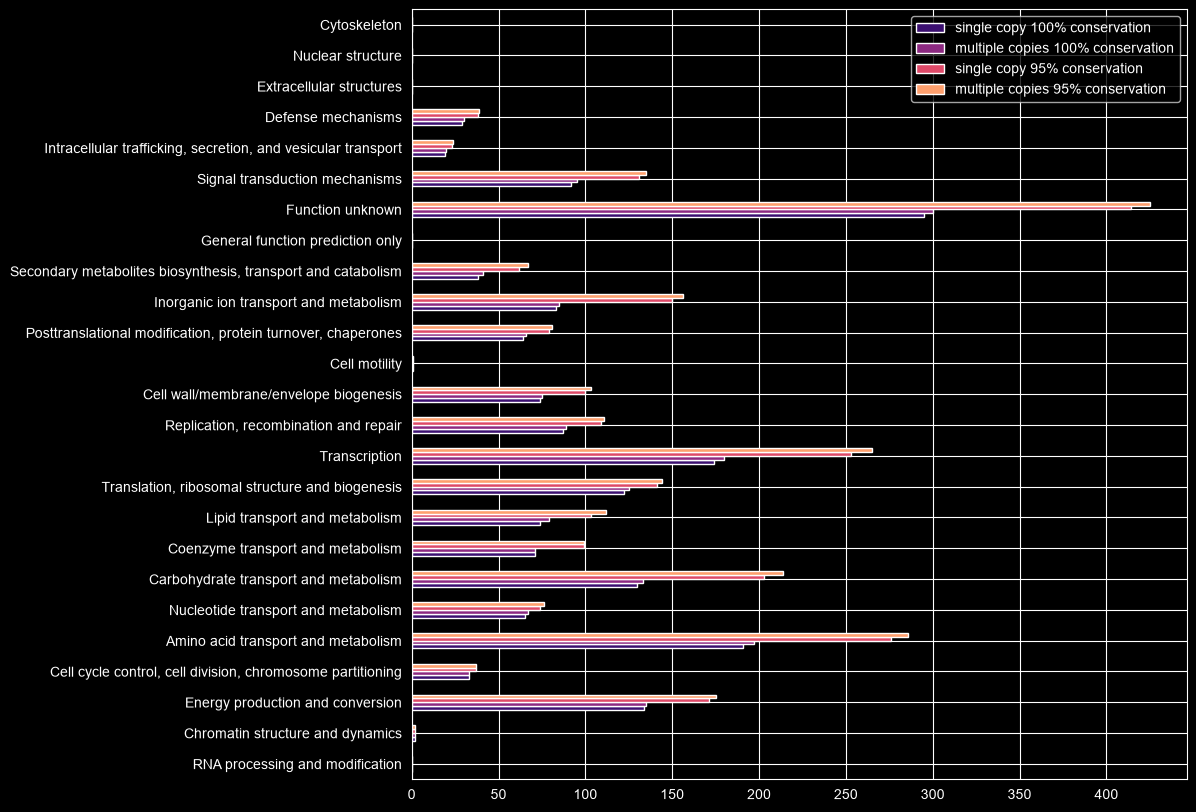

In [17]:
# Can't stack the bars since they are total counts!!!
# Could stack them and calculate difference mathmematically if dropping one dataset, e.g single copy 95%!
# Drop the Nan row
my_palette = sns.color_palette('magma', n_colors=4)
ax3 = eggnog_descriptor_summary_all.plot(kind='barh', color=my_palette, figsize=(10,10))
#ax3.legend(bbox_to_anchor=(1.01, 1.01), loc='upper right', borderaxespad=0.)
ax3.set(ylabel=None)
plt.show()

In [18]:
# Calculate the differences to make a nicer stacked bar graph for 4 categories -> USE ABOVE FOR ALL FOUR
# Calculate the differences to make a nicer stacked bar graph
# Note that the columns with the same name here are now the difference between the respective column!
eggnog_descriptor_summary_fig_df = eggnog_descriptor_summary_all.copy()
eggnog_descriptor_summary_fig_df["multi-single"] = eggnog_descriptor_summary_all["multiple copies 100% conservation"] - eggnog_descriptor_summary_all["single copy 100% conservation"]
eggnog_descriptor_summary_fig_df["95-single-100"] = eggnog_descriptor_summary_all["single copy 95% conservation"] - eggnog_descriptor_summary_all["multiple copies 100% conservation"]
eggnog_descriptor_summary_fig_df["multi-95-single"] = eggnog_descriptor_summary_all["multiple copies 95% conservation"] - eggnog_descriptor_summary_all["single copy 95% conservation"]
eggnog_descriptor_summary_fig_df.drop(columns=["multiple copies 100% conservation", "single copy 95% conservation", "multiple copies 95% conservation"], inplace=True)
eggnog_descriptor_summary_fig_df.rename(columns={"multi-single":"multiple copies 100% conservation", "95-single-100":"single copy 95% conservation", "multi-95-single":"multiple copies 95% conservation"}, inplace=True)
eggnog_descriptor_summary_fig_df

,single copy 100% conservation,multiple copies 100% conservation,single copy 95% conservation,multiple copies 95% conservation
1,,,,
RNA processing and modification,NaN,NaN,NaN,NaN
Chromatin structure and dynamics,2.0,0.0,0.0,0.0
Energy production and conversion,134.0,1.0,36.0,4.0
"Cell cycle control, cell division, chromosome partitioning",33.0,0.0,4.0,0.0
Amino acid transport and metabolism,191.0,6.0,79.0,10.0
Nucleotide transport and metabolism,65.0,2.0,7.0,2.0
Carbohydrate transport and metabolism,130.0,3.0,70.0,11.0
Coenzyme transport and metabolism,71.0,0.0,28.0,0.0
Lipid transport and metabolism,74.0,5.0,24.0,9.0


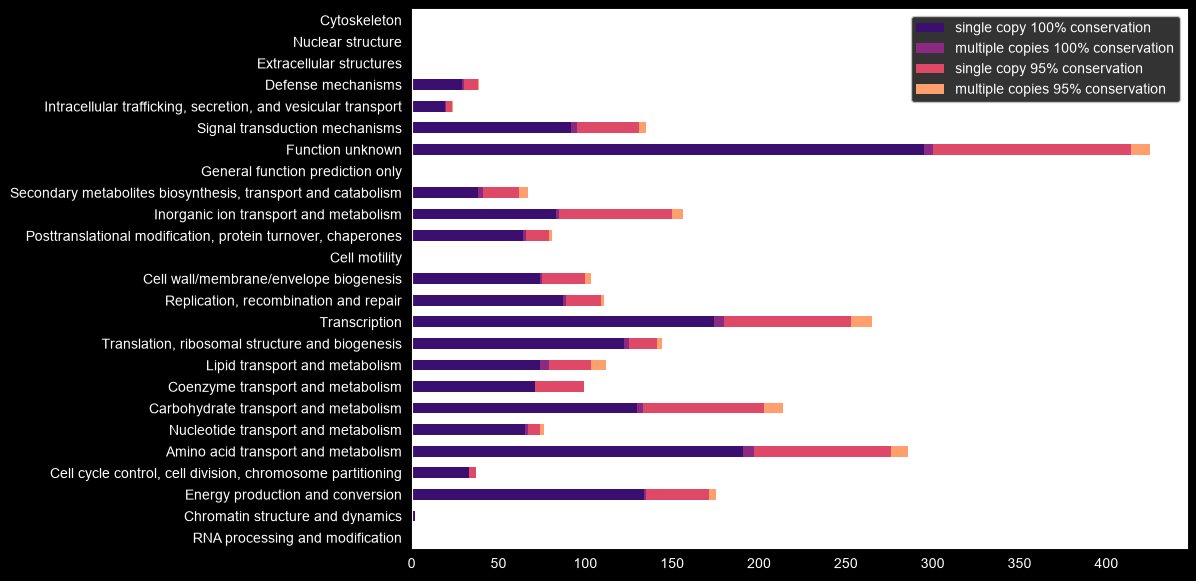

In [19]:
# Plot the graph with the difference, i.e. genes added by each pangenome parameter change
my_palette = sns.color_palette('magma', n_colors=4)
ax4 = eggnog_descriptor_summary_fig_df.plot(kind='barh', stacked=True, color=my_palette, figsize=(10,7), grid=False, edgecolor='none')
#ax3.legend(bbox_to_anchor=(1.01, 1.01), loc='upper right', borderaxespad=0.)
ax4.set(ylabel=None)
# Not sure why but keeps printing as balck figure sometimes, have to change how to specify the background here for it to save as white
ax4.set_facecolor('white')
#plt.savefig("Corepers_4_variations_eggNOG_COGs.png", bbox_inches='tight', dpi=600)
plt.show()

#### Make a summary of annotated genes per strain for Figure 1

In [20]:
# Create a new dataframe with only the strain identifier and the COG category
MICB_strain_annotation_summary_df = pd.DataFrame()
MICB_strain_annotation_summary_df["strain"] = MICB_all_eggnog_df["#query"].str.split(".", expand=True)[0]
MICB_strain_annotation_summary_df["COG_category"] = MICB_all_eggnog_df["COG_category"]
MICB_strain_annotation_summary_df.tail (5)


,strain,COG_category
306949,TRIR,-
306950,TRIR,P
306951,TRIR,S
306952,TRIR,S
306953,TRIR,K


In [21]:
MICB_tmp1 = MICB_strain_annotation_summary_df["strain"].value_counts().reset_index()
MICB_tmp1.rename(columns={"count":"total"}, inplace=True)
MICB_tmp2 = MICB_strain_annotation_summary_df[MICB_strain_annotation_summary_df["COG_category"] == "S"].value_counts().reset_index()
MICB_tmp2.rename(columns={"count":"S"}, inplace=True)
MICB_strain_annotation_summary_out = pd.merge(MICB_tmp1, MICB_tmp2, on="strain", how='left')
MICB_strain_annotation_summary_out["annotated"] = MICB_strain_annotation_summary_out['total'] - MICB_strain_annotation_summary_out['S']
MICB_strain_annotation_summary_out.drop(columns=["COG_category",'total'], inplace=True)
MICB_strain_annotation_summary_out = MICB_strain_annotation_summary_out[["strain","annotated","S"]]
#MICB_strain_annotation_summary_out.to_csv("MICB_strain_annotation_stats_clean.csv", index=False, header=False)
MICB_strain_annotation_summary_out


,strain,annotated,S
0,CA18,7157,1509
1,SITR,7085,1507
2,CA04,7063,1516
3,CA17,6905,1487
4,CA08,6869,1498
5,CA13,6763,1478
6,635G,6803,1397
7,CA16,6711,1463
8,CA03,6707,1458
9,CA20,6666,1475


## Analyse the pangenome functions

In [22]:
# Import all gene family summary and merge with eggnog results
# Note this only takes the first entry of the gene family. Some other annotations could potentially be better.
all_gf_df = pd.read_csv("PanGenome-MICB.All.prt-clust-0.8-mode1-th8.clean.lst", sep=r'\s{1}', header=None, engine='python', usecols=[0, 1])
all_gf_df.rename(columns={0: 'PanACoTA_gene_family', 1: 'gene_id'}, inplace=True)
print(len(all_gf_df))
all_gf_eggnog_df = pd.merge(all_gf_df, MICB_all_eggnog_df, left_on='gene_id', right_on='#query', how='left')
all_gf_eggnog_df.drop(columns=['gene_id'], inplace=True)
print(len(all_gf_eggnog_df))

51078
51078


#### COG descriptor summary

In [23]:
# Summarise all single COG descriptors
all_gf_COG_cat_summary_df = all_gf_eggnog_df["COG_category"].value_counts().to_frame()
index_lengths = all_gf_COG_cat_summary_df.index.map(len)
mask = (index_lengths == 1)
all_gf_COG_cat_summary_singles_df = all_gf_COG_cat_summary_df[mask]
all_gf_COG_cat_summary_singles_descriptors = pd.merge(all_gf_COG_cat_summary_singles_df, COG_descriptors, left_index=True, right_on=0, how='right')
all_gf_COG_cat_summary_singles_descriptors

,count,0,1
0,620.0,J,"Translation, ribosomal structure and biogenesis"
1,9.0,A,RNA processing and modification
2,5524.0,K,Transcription
3,2706.0,L,"Replication, recombination and repair"
4,NaN,B,Chromatin structure and dynamics
5,357.0,D,"Cell cycle control, cell division, chromosome ..."
6,NaN,Y,Nuclear structure
7,1399.0,V,Defense mechanisms
8,1986.0,T,Signal transduction mechanisms
9,1584.0,M,Cell wall/membrane/envelope biogenesis


#### Now include hybrid COG categories to make final comparison between core and variable genome

In [24]:
pers_gf_M_eggnog_df = summary_eggnog_M_gf_df.copy()
pers_gf_M_eggnog_df.drop(columns=['gene_id'], inplace=True)
print(len(pers_gf_M_eggnog_df))

1776


In [25]:
# COG descriptors contain hybrids, so split them up
df_tmp = pers_gf_M_eggnog_df["COG_category"].str.split('', expand=True)
# The split operation often adds an empty string column at the start and end (due to start and end of string boundaries)
df_tmp = df_tmp.drop(columns=[0, df_tmp.shape[1]-1])
df_tmp = df_tmp.stack().dropna().value_counts().to_frame()
# Delete the first row, which counts empty cells?
df_tmp = df_tmp.iloc[1:]
pers_gf_M_eggnog_COG_descriptor_df = pd.merge(df_tmp, COG_descriptors, left_on=df_tmp.index, right_on=0, how='right')
print(pers_gf_M_eggnog_COG_descriptor_df["count"].sum())
pers_gf_M_eggnog_COG_descriptor_df.rename(columns={'count':'multiple copies 100% conservation'}, inplace=True)
pers_gf_M_eggnog_COG_descriptor_df


1824.0


,multiple copies 100% conservation,0,1
0,125.0,J,"Translation, ribosomal structure and biogenesis"
1,NaN,A,RNA processing and modification
2,180.0,K,Transcription
3,89.0,L,"Replication, recombination and repair"
4,2.0,B,Chromatin structure and dynamics
5,33.0,D,"Cell cycle control, cell division, chromosome ..."
6,NaN,Y,Nuclear structure
7,30.0,V,Defense mechanisms
8,95.0,T,Signal transduction mechanisms
9,75.0,M,Cell wall/membrane/envelope biogenesis


In [26]:
# Created dataframe with variable genome annotations
# Dataset encompasses 324,392 genes (MICB.All.prt input file) of which 306,955 genes were annotated by eggNOG
# So 17,437 not annotated, which likely leads to the Nan values when merging the MICB eggnog dataframe with the gene family dataframe! Spot-checked and these entries appear to be hypothetical proteins
pers_gf_M_lst = pers_gf_M_eggnog_df["#query"].tolist()
print(len(pers_gf_M_lst))
variable_gf_eggnog_df = all_gf_eggnog_df[all_gf_eggnog_df['#query'].isin(pers_gf_M_lst) == False]
print(len(variable_gf_eggnog_df))
print(len(all_gf_eggnog_df))
print(len(all_gf_eggnog_df[all_gf_eggnog_df["COG_category"].isna() == True]))


1776
41008
51078
8302


In [27]:
# Calculate COG category counts including hybrids for the variable genome
# Note that this excludes 8,294 and 8 unannotated genes from MICB and pers_gf_M_eggnog_df respectively
df_tmp = variable_gf_eggnog_df["COG_category"].str.split('', expand=True)
# The split operation often adds an empty string column at the start and end (due to start and end of string boundaries)
df_tmp = df_tmp.drop(columns=[0, df_tmp.shape[1]-1])
df_tmp = df_tmp.stack().dropna().value_counts().to_frame()
# Delete the first row, which counts empt cells?
df_tmp = df_tmp.iloc[1:]
variable_gef_eggnog_COG_descriptor_df = pd.merge(df_tmp, COG_descriptors, left_on=df_tmp.index, right_on=0, how='right')
print(variable_gef_eggnog_COG_descriptor_df["count"].sum())
variable_gef_eggnog_COG_descriptor_df.rename(columns={'count':'variable pangenome'}, inplace=True)
variable_gef_eggnog_COG_descriptor_df


40048.0


,variable pangenome,0,1
0,573.0,J,"Translation, ribosomal structure and biogenesis"
1,9.0,A,RNA processing and modification
2,6158.0,K,Transcription
3,3104.0,L,"Replication, recombination and repair"
4,1.0,B,Chromatin structure and dynamics
5,375.0,D,"Cell cycle control, cell division, chromosome ..."
6,NaN,Y,Nuclear structure
7,1383.0,V,Defense mechanisms
8,2696.0,T,Signal transduction mechanisms
9,1912.0,M,Cell wall/membrane/envelope biogenesis


In [28]:
pers_gf_sum = pers_gf_M_eggnog_COG_descriptor_df["multiple copies 100% conservation"].sum()
variable_gf_sum = variable_gef_eggnog_COG_descriptor_df["variable pangenome"].sum()
final_core_variable_comp_df = pd.merge(pers_gf_M_eggnog_COG_descriptor_df, variable_gef_eggnog_COG_descriptor_df, on=1)
final_core_variable_comp_df.drop(columns=['0_x','0_y'], inplace=True)
final_core_variable_comp_df['core %'] = final_core_variable_comp_df['multiple copies 100% conservation']/pers_gf_sum*100
final_core_variable_comp_df['variable %'] = final_core_variable_comp_df['variable pangenome']/variable_gf_sum*100
final_core_variable_comp_df

,multiple copies 100% conservation,1,variable pangenome,core %,variable %
0,125.0,"Translation, ribosomal structure and biogenesis",573.0,6.853070,1.430783
1,NaN,RNA processing and modification,9.0,NaN,0.022473
2,180.0,Transcription,6158.0,9.868421,15.376548
3,89.0,"Replication, recombination and repair",3104.0,4.879386,7.750699
4,2.0,Chromatin structure and dynamics,1.0,0.109649,0.002497
5,33.0,"Cell cycle control, cell division, chromosome ...",375.0,1.809211,0.936376
6,NaN,Nuclear structure,NaN,NaN,NaN
7,30.0,Defense mechanisms,1383.0,1.644737,3.453356
8,95.0,Signal transduction mechanisms,2696.0,5.208333,6.731922
9,75.0,Cell wall/membrane/envelope biogenesis,1912.0,4.111842,4.774271


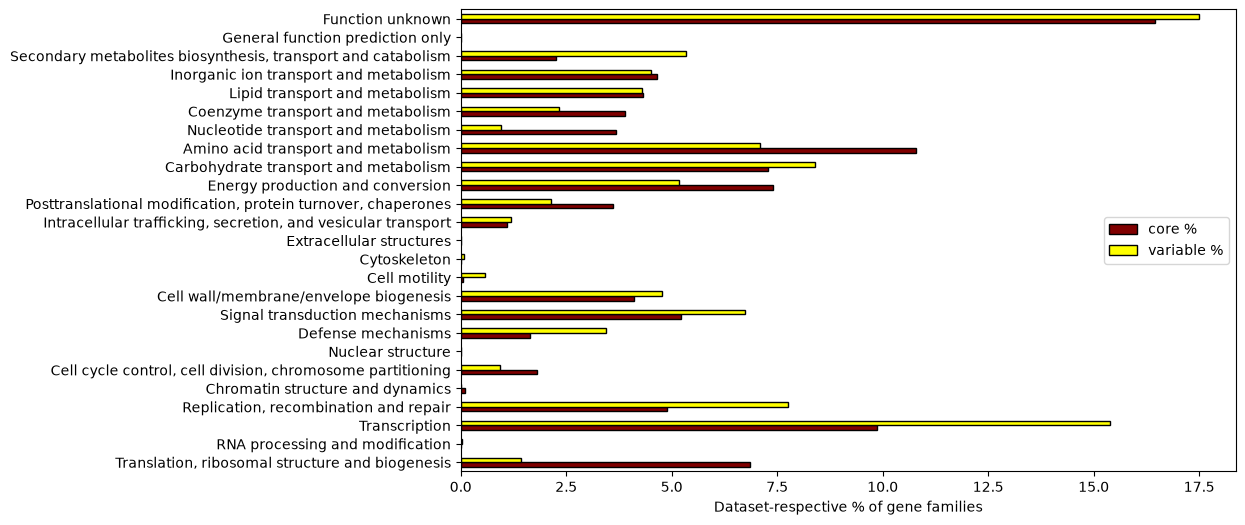

In [29]:
# Drop NaN artifact row and make a bar graph of the percentages
#final_core_variable_comp_df
plt.style.use('default')
ax5 = final_core_variable_comp_df.plot(kind='barh', x=1, y=["core %", "variable %"], color=['maroon','yellow'], grid=False, figsize=(10,6), edgecolor='black')
#ax3.legend(bbox_to_anchor=(1.01, 1.01), loc='upper right', borderaxespad=0.)
ax5.set(xlabel='Dataset-respective % of gene families')
ax5.set(ylabel=None)
# Not sure why but had to specify the background here for it to save as white
#plt.savefig("Final_core_variable_COG_comparison_clean.png", bbox_inches='tight', dpi=600)
plt.show()

## KEGG pathway number for visualisation in KEGG Mapper

In [66]:
pers_KEGG_list = pers_gf_M_eggnog_df["KEGG_ko"].str.split(",").explode().unique().tolist()
print(len(pers_KEGG_list))
tmp_pers_KEGG_list = pd.Series(pers_KEGG_list).dropna().tolist()
print(len(tmp_pers_KEGG_list))
clean_pers_KEGG_list = [s[3:] for s in tmp_pers_KEGG_list]
print(len(clean_pers_KEGG_list))



1067
1066
1066


In [68]:
df = pd.DataFrame(clean_pers_KEGG_list, columns=["value"])
# Write to TSV, keeping the index column
#df.to_csv("KEGG_pathways_persistent.tsv", sep="\t", index=True, header=False)

In [70]:
variable_KEGG_list = variable_gf_eggnog_df["KEGG_ko"].str.split(",").explode().unique().tolist()
print(len(variable_KEGG_list))
tmp_variable_KEGG_list = pd.Series(variable_KEGG_list).dropna().tolist()
print(len(tmp_variable_KEGG_list))
clean_variable_KEGG_list = [s[3:] for s in tmp_variable_KEGG_list]
print(len(clean_variable_KEGG_list))

2359
2359
2359


In [71]:
df = pd.DataFrame(clean_variable_KEGG_list, columns=["value"])
# Write to TSV, keeping the index column
df.to_csv("KEGG_pathways_variable.tsv", sep="\t", index=True, header=False)

## Plant host interaction-related genes in the core pangenome

In [74]:
pers_gf_M_eggnog_df.columns

Index(['PanACoTA_gene_family', '#query', 'evalue', 'COG_category',
       'Description', 'Preferred_name', 'GOs', 'EC', 'KEGG_ko', 'KEGG_Pathway',
       'KEGG_Reaction', 'BRITE', 'KEGG_TC', 'CAZy', 'PFAMs'],
      dtype='object')

In [71]:
# Search the core genome for many key words and genes (Note CAZymes area analysed via CAZyme column)
pd.options.display.max_colwidth = None
# PLANT GROWTH PROMOTION
# Check for ACCD. Note the gene abbreviation is acdS and accD are other genes
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Description"].str.contains("|".join(["1-aminocyclopropane", "ACCD", "ethylene"]), case=False, na=False)])
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("acdS", case=False, na=False)])
#Check for other plant hormones regulations
# Omitted "cupin", "IAA", "IBA" and "PAA", "aldA", "tam" because of misleading results
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("|".join(["ipdC", "iaaM", "iaaH", "TAA1", "hopA1", "YUC", "ipd1", "amiE", "iad", "tso", "aldh", "aux1", "aro8", "aro9", "tdc", "aad", "y4wf", "tidC", "nit", "yhcX", "ntha", "nthB"]), case=False, na=False)])
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["EC"].str.contains("|".join(["EC 2.6.1.27", "EC 3.5.5.1"]), case=False, na=False)])
pers_IAA_or_PAA_genes = pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["KEGG_ko"].str.contains("|".join([" K01593", "K00274", "K00128", "K01501"]), case=False, na=False)]
pers_IAA_or_PAA_lists = pers_IAA_or_PAA_genes.groupby('KEGG_ko')['PanACoTA_gene_family'].apply(list).to_frame()
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Description"].str.contains("|".join(["auxin", "indole-3-acetic acid", "4-chloroindole-3-acetic acid", "tryptophan", "IAM hydrolase", "aspC-like", "tyrB-like", "amiE-like", "gatA-like", "CYP79",  "phenylacetic acid", "indole-3-butyric acid", "cytokinin", "gibberellin", "abscisic acid", "YUC-like flavin-containing monooxygenases", "yucca-like"]), case=False, na=False)])

# Check for Nitrogen fixing
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("|".join(["nif", "fix"]), case=False, na=False)])
# Check for Phosphorus extraction
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("|".join(["pqq", "gcd"]), case=False, na=False)])
# Check for Iron delivery and siderophores
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("|".join(["ent", "pvd", "acr"]), case=False, na=False)])
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Description"].str.contains("|".join(["siderophore", "chelating"]), case=False, na=False)])

# PLANT HOST ATTACHMENT AND INVASION
# Check for chemotaxis, motility and adhesion
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("|".join(["che", "mot", "fli", "pil", "tad", "dgc", "bcs"]), case=False, na=False)])
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Description"].str.contains("|".join(["chemotaxis", "motility", "flagellum", "flagella", "pili", "pilus", "fimbriae", "cellulose synthase"]), case=False, na=False)])
# Biofilm formation
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("|".join(["pel", "psl", "alg", "Wxl"]), case=False, na=False)])
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Description"].str.contains("|".join(["biofilm", "adhesion", "peptidoglycan binding", "PGBD", "WxlIP", "DUF916", "DUF3324"]), case=False, na=False)])
# Host invasion and interaction
# Removed "hrp" because of misleading results
pers_plant_genes_1 = pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("|".join(["kat", "sod", "vir"]), case=False, na=False)]
pers_plant_genes_1_lists = pers_plant_genes_1.groupby('Preferred_name')['PanACoTA_gene_family'].apply(list).to_frame()

#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Description"].str.contains("|".join(["LPG", "secretion system", "pathogenesis", "phyto", "plant", "host", "effector", "eukaryot", "hemoglobin"]), case=False, na=False)])

# PLANT HOST DEFENSE AGAINST PATHOGENS
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Preferred_name"].str.contains("|".join(["phl", "phz", "chiA",]), case=False, na=False)])
#print(pers_gf_M_eggnog_df[pers_gf_M_eggnog_df["Description"].str.contains("|".join(["jasmonic acid", "jasmonate", "salicylic acid", "phenylpropanoid", "2,4-di-tert-butylphenol"]), case=False, na=False)])


In [75]:
# CAZyme summary.
# The frist two lines will print a dataframe with a simple count summary of CAZyme classes.
#pers_CAZyme_sumamry_df = pers_gf_M_eggnog_df[pers_gf_M_eggnog_df['CAZy'] != "-"]["CAZy"].value_counts().to_frame()
#print(pers_CAZyme_sumamry_df)

# Establish search patterns for relevant CAZyme families
xylanases_list = ["GH10", "GH11", "GH12"]
xylanases_pattern = '|'.join(xylanases_list)
arabinoxylanases_list = ["GH43", "GH51", "GH54", "GH62"]
arabinoxylanases_pattern = '|'.join(arabinoxylanases_list)
glucanases_list = ["GH3", "GH5", "GH7", "GH9", "GH45", "GH51"]
glucanases_pattern = '|'.join(glucanases_list)
pectinases_list = ["PL1", "PL2", "PL3", "PL4", "CE8", "CE12", "CE13", "GH28"]
pectinases_pattern = '|'.join(pectinases_list)
surface_penetration_list = ["CE1", "CE5", "AA9"]
surface_penetration_pattern = '|'.join(surface_penetration_list)
ligninases_list = ["AA1", "AA2"]
ligninases_pattern = '|'.join(ligninases_list)
immune_evasion_list = ["CE4", "AA7", "AA17", "AA14", "CBM50"]
immune_evasion_pattern = '|'.join(immune_evasion_list)
chitinase_LPMO_list = ["GH18", "GH19", "AA10", "AA11"]
chitinase_LPMO_pattern = '|'.join(chitinase_LPMO_list)
chitin_binding_list = ["CBM5", "CBM12", "CBM14", "CBM73", "CBM1", "CBM18"]
chitin_binding_pattern = '|'.join(chitin_binding_list)

CAZyme_patterns = [xylanases_pattern, arabinoxylanases_pattern, glucanases_pattern, pectinases_pattern, surface_penetration_pattern, ligninases_pattern, immune_evasion_pattern, chitinase_LPMO_pattern, chitin_binding_pattern]

In [76]:
# Combine CAZy pattern and identify CAZyme families
combined_CAZy_pattern = '|'.join(CAZyme_patterns)
pers_priority_CA_df = pers_gf_M_eggnog_df[pers_gf_M_eggnog_df['CAZy'].str.contains(combined_CAZy_pattern, case=False, na=False)]
pers_CAZyme_lists = pers_priority_CA_df.groupby('CAZy')['PanACoTA_gene_family'].apply(list).to_frame()
# Note this CAZyme search returned some incorrect
pers_CAZyme_lists.drop(index=["GH31"], inplace=True)
pers_CAZyme_lists

,PanACoTA_gene_family
CAZy,
"AA10,CBM73",[33431]
GH3,"[38718, 44031]"
"GH5,GH66,GH9",[5454]
"GH5,GH9","[4244, 30827]"


#### Plant host interaction-related genes in the variable pangenome

In [81]:
# Search the variable genome for many key words and genes (Note CAZymes area analysed via CAZyme column)

# RESULTS OBTAINED FOR
# "1-aminocyclopropane"
# Several results for "biofilm", "adhesion", "peptidoglycan binding" and "DUF916"
# Several results for "fagellum", "pilus" and
# Several results for "pathogen"
# Several secretion systems, e.g. Type II, Type II/IV and Type IV (sometimes II is in lower case ii), but also Type VII

# Search the core genome for many key words and genes (Note CAZymes area analysed via CAZyme column)
pd.options.display.max_colwidth = None
# PLANT GROWTH PROMOTION
# Check for ACCD. Note the gene abbreviation is acdS and accD are other genes.
# Omitted "ethylene" because of misleading results
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["1-aminocyclopropane", "ACCD"]), case=False, na=False)])
variable_ACCD_df = variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["1-aminocyclopropane", "ACCD"]), case=False, na=False)]
variable_ACCD_df_lists = variable_ACCD_df.groupby('Description')['PanACoTA_gene_family'].apply(list).to_frame()
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Preferred_name"].str.contains("acdS", case=False, na=False)])
#Check for other plant hormones regulations
# Omitted "cupin", "IAA", "IBA" and "PAA", "aldA", "tam" because of misleading results
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Preferred_name"].str.contains("|".join(["ipdC", "iaaM", "iaaH", "TAA1", "hopA1", "YUC", "ipd1", "amiE", "iad", "tso", "aldh", "aux1", "aro8", "aro9", "tdc", "aad", "y4wf", "tidC", "nit", "yhcX", "ntha", "nthB"]), case=False, na=False)])
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["EC"].str.contains("|".join(["EC 2.6.1.27", "EC 3.5.5.1"]), case=False, na=False)])
var_IAA_or_PAA_genes = variable_gf_eggnog_df[variable_gf_eggnog_df["KEGG_ko"].str.contains("|".join([" K01593", "K00274", "K00128", "K01501"]), case=False, na=False)]
var_IAA_or_PAA_lists = var_IAA_or_PAA_genes.groupby('KEGG_ko')['PanACoTA_gene_family'].apply(list).to_frame()
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["auxin", "indole-3-acetic acid", "4-chloroindole-3-acetic acid", "tryptophan", "IAM hydrolase", "aspC-like", "tyrB-like", "amiE-like", "gatA-like", "CYP79",  "phenylacetic acid", "indole-3-butyric acid", "cytokinin", "gibberellin", "abscisic acid", "YUC-like flavin-containing monooxygenases", "yucca-like"]), case=False, na=False)]["KEGG_ko"].str.split(":", expand=True)[1].tolist())
# Check for Nitrogen fixing
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Preferred_name"].str.contains("|".join(["nif", "fix"]), case=False, na=False)])
# Check for Phosphorus extraction
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["gluconic acid"]), case=False, na=False)])
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Preferred_name"].str.contains("|".join(["pqq", "gcd"]), case=False, na=False)])
# Check for Iron delivery and siderophores
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Preferred_name"].str.contains("|".join(["ent", "pvd", "acr"]), case=False, na=False)])
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["siderophore", "chelating"]), case=False, na=False)])

# PLANT HOST ATTACHMENT AND INVASION
# Check for chemotaxis, motility and adhesion
# Removed "Preferred_name" search for "che", "mot", "fli", "pil", "tad", "dgc", "bcs", since they returned non-relevant and below search captures the relevant
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["chemotaxis", "motility", "flagellum", "flagella", "pili", "pilus", "fimbriae", "cellulose synthase"]), case=False, na=False)])
variable_motility_df = variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["chemotaxis", "motility", "flagellum", "flagella", "pili", "pilus", "fimbriae", "cellulose synthase"]), case=False, na=False)]
variable_motility_df_lists = variable_motility_df.groupby('Description')['PanACoTA_gene_family'].apply(list).to_frame()
# Biofilm formation
# Removed "Preferred_name" search for "pel", "psl", "alg", "Wxl", since they returned non-relevant and below search captures the relevant
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["biofilm", "adhesion", "peptidoglycan binding", "PGBD", "WxlIP", "DUF916", "DUF3324"]), case=False, na=False)])
variable_biofilm_df = variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["biofilm", "adhesion", "peptidoglycan binding", "PGBD", "WxlIP", "DUF916", "DUF3324"]), case=False, na=False)]
variable_biofilm_df_lists = variable_biofilm_df.groupby('Description')['PanACoTA_gene_family'].apply(list).to_frame()
# Host invasion and interaction
# Removed "hrp" because of misleading results and "sod" to simplify
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Preferred_name"].str.contains("|".join(["cat", "kat", "vir"]), case=False, na=False)])
variable_kat_df = variable_gf_eggnog_df[variable_gf_eggnog_df["Preferred_name"].str.contains("|".join(["cat", "kat", "vir"]), case=False, na=False)]
variable_kat_df_lists = variable_kat_df.groupby('Preferred_name')['PanACoTA_gene_family'].apply(list).to_frame()
# Removed "eukaryot", "phyto", "plant", "host", "effector", "hemoglobin", because of misleading results
variable_host_df = variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["Neu5Ac", "LPG", "MsrPQ", "pathogenesis", "Hrp", "secretion system"]), case=False, na=False)]
variable_host_df_lists = variable_host_df.groupby('Description')['PanACoTA_gene_family'].apply(list).to_frame()

# PLANT HOST DEFENSE AGAINST PATHOGENS
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Preferred_name"].str.contains("|".join(["phl", "phz", "chiA",]), case=False, na=False)])
#print(variable_gf_eggnog_df[variable_gf_eggnog_df["Description"].str.contains("|".join(["jasmonic acid", "jasmonate", "salicylic acid", "phenylpropanoid", "2,4-di-tert-butylphenol"]), case=False, na=False)])


variable_df_lists = pd.concat([variable_kat_df_lists, var_IAA_or_PAA_lists, variable_biofilm_df_lists, variable_motility_df_lists, variable_ACCD_df_lists, variable_host_df_lists])
variable_df_lists



,PanACoTA_gene_family
katA,[477]
katE,"[27443, 48127]"
ko:K00128,"[6062, 11953, 30067]"
"ko:K00128,ko:K00130","[25540, 26478, 27570, 39355, 45767]"
"ko:K00128,ko:K00146",[18199]
ko:K00274,"[2150, 33319, 41053, 48981]"
"ko:K00274,ko:K03343",[42679]
ko:K01501,"[662, 24193]"
Bacterial protein of unknown function (DUF916),"[2605, 6822, 15161, 38563, 40524, 42477, 43003, 44380, 44793, 46078]"
Putative peptidoglycan binding domain,"[2243, 2251, 6546, 9202, 9802, 12750, 13625, 13766, 14235, 14572, 18050, 18111, 20539, 23037, 24301, 25064, 26652, 30050, 32134, 32635, 36188, 37422, 39489, 42120, 42341, 44555, 44597, 45146, 45750, 48894, 50867]"


In [82]:
# References the priority list created above
variable_priority_CAZ_df = variable_gf_eggnog_df[variable_gf_eggnog_df['CAZy'].str.contains(combined_CAZy_pattern, case=False, na=False)]
variable_CAZyme_lists = variable_priority_CAZ_df.groupby('CAZy')['PanACoTA_gene_family'].apply(list).to_frame()
# Note this CAZyme search returned some incorrect
variable_CAZyme_lists.drop(index=["GH51", "CBM42,GH54", "CE10", "GH105", "GH43,GH51", "GH51", "CBM50", "GH13,GH31", "GH26,GH31", "GH30", "GH31", "GH32", "GH33", "GH37", "GH38", "GH39", "GH95"], inplace=True)
variable_CAZyme_lists

,PanACoTA_gene_family
CAZy,
AA10,"[5134, 19178, 29339, 32493, 43342, 46185, 47458, 49606]"
"AA10,CBM73","[2533, 3640, 4614, 6234, 6302, 8865, 9157, 13425, 14642, 20741, 22948, 23420, 27780, 29962, 32038, 33046, 37199, 42404, 42559, 44935, 45115, 46978, 49189, 49450, 50911]"
"CBM6,GH43","[4706, 47206]"
CE1,"[13024, 24383, 45208]"
GH18,"[1259, 1906, 4796, 5557, 6572, 13044, 13427, 14327, 15493, 15620, 15968, 16239, 17144, 18550, 18970, 21749, 23162, 23456, 25363, 27527, 30697, 31521, 31561, 32596, 34229, 36281, 38334, 40938, 42197, 42687, 42715, 43997, 45412, 48858, 50131]"
"GH18,GH5,GH9",[33871]
GH3,"[843, 1014, 1464, 2776, 3289, 3359, 6447, 8821, 9117, 9118, 9161, 10699, 14300, 14738, 14919, 16549, 18543, 19288, 20856, 21018, 21201, 25145, 25688, 25785, 30932, 32384, 35022, 35212, 38596, 40265, 43879, 47034]"
GH43,"[3878, 6996, 7331, 8239, 8801, 10306, 13326, 16044, 21557, 24444, 24887, 31390, 36827, 40009, 42530, 44746, 48716, 48791]"
GH5,"[44561, 46449, 49301]"


### Import the quali dataframe to reference PanACoTA gene family numbers and make a heat-map

In [83]:
MICB_All_quali_df = pd.read_csv("PanGenome-MICB.All.prt-clust-0.8-mode1-th8.lst.quali.clean.txt")


In [85]:
# Summarise double-ups in CAZyme dataframe
CAZyme_lists_df = pd.concat([pers_CAZyme_lists, variable_CAZyme_lists])
CAZyme_lists_sum_df = CAZyme_lists_df.groupby('CAZy')['PanACoTA_gene_family'].sum().to_frame()
# Make one big lists dataframe
gene_lists_df = pd.concat([pers_plant_genes_1_lists, pers_IAA_or_PAA_lists, variable_df_lists, CAZyme_lists_sum_df])


In [88]:
# Could turn this into a function, but some sanity checking was evidently needed
# Step 1: Make a dataframe for the desired search Terms
# Step 2: Group by the unique Description and return the PanACoTA gene family numbers
# Step 3: Look up the gene family numbers in the quali table and make a single column, which denotes presence absence

# Manual curation to shorten names and merge redundancies. Aim is to add gene family counts together.
gene_fams_summary_list = sum(gene_lists_df['PanACoTA_gene_family'], [])
gene_fams_summary_list = list(map(str, gene_fams_summary_list))
#print(gene_fams_summary_list)
# Make a copy containing gene families of potential interest
gene_fams_summary_df = MICB_All_quali_df.loc[:, ["fam_num"] + gene_fams_summary_list]
# Drop irrelevant/misleading results
gene_fams_summary_df.drop(columns = ['47181', '2546', '5744', "6388", "47254", "10193", "20485", "30277", "33781", "47462", '13024', '24383', '45208', '13855'], inplace=True)
# "biofilm" here really almost exclusively returns PGBD and DUF916, which is implied to have the same function
gene_fams_summary_df['PGB & DUF916'] = gene_fams_summary_df[['2605', '6822', '15161', '38563', '40524', '42477', '43003', '44380', '44793', '46078', "25994", "26559", "27367", "35567", "44553", "46610", '34620', "2243", "2251", "6546", "9202", "9802", "12750", "13625", "13766", "14235", "14572", "18050", "18111", "20539", "23037", "24301", "25064", "26652", "30050", "32134", "32635", "36188", "37422", "39489", "42120", "42341", "44555", "44597", "45146", "45750", "48894", "50867"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ['2605', '6822', '15161', '38563', '40524', '42477', '43003', '44380', '44793', '46078', "25994", "26559", "27367", "35567", "44553", "46610", '34620', "2243", "2251", "6546", "9202", "9802", "12750", "13625", "13766", "14235", "14572", "18050", "18111", "20539", "23037", "24301", "25064", "26652", "30050", "32134", "32635", "36188", "37422", "39489", "42120", "42341", "44555", "44597", "45146", "45750", "48894", "50867"], inplace=True)
# Added flgE and negative regulator in here
gene_fams_summary_df['flagellum organisation'] = gene_fams_summary_df[['5593', '27460', "299", "1197", "1415", "1454", "1599", "1756", "2585", "3977", "4097", "4651", "6115", "7336", "8947", "10002", "10900", "11798", "11830", "12186", "12566", "13416", "13833", "13954", "14251", "16626", "17088", "17395", "18420", "18928", "19102", "19224", "19734", "20208", "20246", "20538", "21100", "21167", "22150", "22418", "23478", "23824", "23856", "24733", "25052", "25397", "25574", "26080", "26604", "26838", "28064", "29292", "29604", "30563", "31775", "32571", "33124", "34260", "35064", "35977", "37317", "37702", "37910", "38149", "38235", "39564", "40622", "40922", "41429", "41487", "41561", "41909", "41999", "42500", "43040", "43166", "44397", "45063", "45187", "45617", "46435", "47271", "47489", "49612", "49775", "49951", "50255", "50446"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ['5593', '27460', "299", "1197", "1415", "1454", "1599", "1756", "2585", "3977", "4097", "4651", "6115", "7336", "8947", "10002", "10900", "11798", "11830", "12186", "12566", "13416", "13833", "13954", "14251", "16626", "17088", "17395", "18420", "18928", "19102", "19224", "19734", "20208", "20246", "20538", "21100", "21167", "22150", "22418", "23478", "23824", "23856", "24733", "25052", "25397", "25574", "26080", "26604", "26838", "28064", "29292", "29604", "30563", "31775", "32571", "33124", "34260", "35064", "35977", "37317", "37702", "37910", "38149", "38235", "39564", "40622", "40922", "41429", "41487", "41561", "41909", "41999", "42500", "43040", "43166", "44397", "45063", "45187", "45617", "46435", "47271", "47489", "49612", "49775", "49951", "50255", "50446"], inplace=True)
# Type IV and Tfp pilus are the same, Flp is different but also TypeIV, so collated
# Omitted "pilus organization" and a couple other pilus-related since misleading or unclear
gene_fams_summary_df['Type IV pilus'] = gene_fams_summary_df[["2142", "14225", "15884", "27699", "37249", "37611", "49849", "415", "4424", "12883", "13422", "16346", "19047", "23786", "24067", "26457", "27566", "29264", "29451", "35832", "36538", "39159", "39924", "40788", "43314", "45157", "45495", "46073", "51004", "2456", "5084", "20380", "22100", "29176", "42680"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["2142", "14225", "15884", "27699", "37249", "37611", "49849", "415", "4424", "12883", "13422", "16346", "19047", "23786", "24067", "26457", "27566", "29264", "29451", "35832", "36538", "39159", "39924", "40788", "43314", "45157", "45495", "46073", "51004", "2456", "5084", "20380", "22100", "29176", "42680"], inplace=True)
# ACCD and ACCD activity (n = 2) added together
gene_fams_summary_df['ACCD'] = gene_fams_summary_df[["2372", "22926", "41450", "44960", "46543", "48114", "3689"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["2372", "22926", "41450", "44960", "46543", "48114", "3689"], inplace=True)
# IAA K01593 + K00274 + K00128 and PAA K01501 formation
gene_fams_summary_df['IAA & PAA'] = gene_fams_summary_df[["6062", "11953", "30067", "25540", "26478", "27570", "39355", "45767", "18199", "2150", "33319", "41053", "48981", "42679", "662", "24193"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["6062", "11953", "30067", "25540", "26478", "27570", "39355", "45767", "18199", "2150", "33319", "41053", "48981", "42679", "662", "24193"], inplace=True)
# Pathogenesis, includes LPG production, Neu5Ac conversion
gene_fams_summary_df['pathogenesis & immune evasion'] = gene_fams_summary_df[["1496", "11246", "14849", "17622", "20932", "22400", "27702", "30041", "50212", "12816", "13997", "17500", "1987", "17530"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["1496", "11246", "14849", "17622", "20932", "22400", "27702", "30041", "50212", "12816", "13997", "17500", "1987", "17530"], inplace=True)
# Stress & host tolerance includes Catalases, dismutases and MsrPQ-associated
gene_fams_summary_df['Stress & host tolerance'] = gene_fams_summary_df[['477', '564', '14854', '27443', '48127', "2188", "19150", "24390"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ['477', '564', '14854', '27443', '48127', "2188", "19150", "24390"], inplace=True)
# Secretion systems
# Omitted '13855':'Hrp_T3SS' since only fond in one strain
# Combined Type II and IV since there appears to be some overlap
gene_fams_summary_df['T2SS & T4SS'] = gene_fams_summary_df[["3584", "35209", "4003", "4992", "9201", "13908", "27654", "50722", "15632", "19499", "19554", "49221", "1040", "36482", "2359", "4923", "8638", "27151", "49394", "10137", "15021", "25685", "32430", "35525", "40470", "4824", "30802", "33182", "33531", "40977", "41664", "43701", "50301", "10983", "13501", "22467", "28224", "33002", "45780"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["3584", "35209", "4003", "4992", "9201", "13908", "27654", "50722", "15632", "19499", "19554", "49221", "1040", "36482", "2359", "4923", "8638", "27151", "49394", "10137", "15021", "25685", "32430", "35525", "40470", "4824", "30802", "33182", "33531", "40977", "41664", "43701", "50301", "10983", "13501", "22467", "28224", "33002", "45780"], inplace=True)
# WXG100 protein secretion system (Wss), protein YukD, apparently part of T7SS
gene_fams_summary_df['T7SS'] = gene_fams_summary_df[["5487", "613", "18985", "32584", "23095"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["5487", "613", "18985", "32584", "23095"], inplace=True)
# CAZymes
# Omitted "CE1" results since they are seemingly general (carboxyl)esterases
gene_fams_summary_df['glucanases'] = gene_fams_summary_df[["44561", "46449", "49301", "4244", "30827", "1789", "5435", "5904", "6348", "6787", "8359", "9113", "9745", "10047", "10551", "11772", "12352", "12627", "12690", "13755", "14611", "14991", "16720", "17326", "17407", "17417", "18402", "18837", "19467", "19585", "21877", "23442", "23611", "24714", "24781", "24966", "27061", "28085", "30011", "30979", "31171", "31861", "32507", "37957", "41780", "42064", "44528", "44770", "45009", "47906", "48776", "50659", "5454", "5181", "18238", "21977", "31509", "33079", "33283", "48734", "49898", "38718", "44031", "843", "1014", "1464", "2776", "3289", "3359", "6447", "8821", "9117", "9118", "9161", "10699", "14300", "14738", "14919", "16549", "18543", "19288", "20856", "21018", "21201", "25145", "25688", "25785", "30932", "32384", "35022", "35212", "38596", "40265", "43879", "47034"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["44561", "46449", "49301", "4244", "30827", "1789", "5435", "5904", "6348", "6787", "8359", "9113", "9745", "10047", "10551", "11772", "12352", "12627", "12690", "13755", "14611", "14991", "16720", "17326", "17407", "17417", "18402", "18837", "19467", "19585", "21877", "23442", "23611", "24714", "24781", "24966", "27061", "28085", "30011", "30979", "31171", "31861", "32507", "37957", "41780", "42064", "44528", "44770", "45009", "47906", "48776", "50659", "5454", "5181", "18238", "21977", "31509", "33079", "33283", "48734", "49898", "38718", "44031", "843", "1014", "1464", "2776", "3289", "3359", "6447", "8821", "9117", "9118", "9161", "10699", "14300", "14738", "14919", "16549", "18543", "19288", "20856", "21018", "21201", "25145", "25688", "25785", "30932", "32384", "35022", "35212", "38596", "40265", "43879", "47034"], inplace=True)
gene_fams_summary_df['chitinase & chitin-binding'] = gene_fams_summary_df[["1259", "1906", "4796", "5557", "6572", "13044", "13427", "14327", "15493", "15620", "15968", "16239", "17144", "18550", "18970", "21749", "23162", "23456", "25363", "27527", "30697", "31521", "31561", "32596", "34229", "36281", "38334", "40938", "42197", "42687", "42715", "43997", "45412", "48858", "50131", "33871", "5134", "19178", "29339", "32493", "43342", "46185", "47458", "49606", "33431", "2533", "3640", "4614", "6234", "6302", "8865", "9157", "13425", "14642", "20741", "22948", "23420", "27780", "29962", "32038", "33046", "37199", "42404", "42559", "44935", "45115", "46978", "49189", "49450", "50911"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["1259", "1906", "4796", "5557", "6572", "13044", "13427", "14327", "15493", "15620", "15968", "16239", "17144", "18550", "18970", "21749", "23162", "23456", "25363", "27527", "30697", "31521", "31561", "32596", "34229", "36281", "38334", "40938", "42197", "42687", "42715", "43997", "45412", "48858", "50131", "33871"], inplace=True)
gene_fams_summary_df['arabinoxylanases'] = gene_fams_summary_df[["3878", "6996", "7331", "8239", "8801", "10306", "13326", "16044", "21557", "24444", "24887", "31390", "36827", "40009", "42530", "44746", "48716", "48791", "4706", "47206"]].sum(axis=1)
gene_fams_summary_df.drop(columns = ["3878", "6996", "7331", "8239", "8801", "10306", "13326", "16044", "21557", "24444", "24887", "31390", "36827", "40009", "42530", "44746", "48716", "48791", "4706", "47206", "5134", "19178", "29339", "32493", "43342", "46185", "47458", "49606", "33431", "2533", "3640", "4614", "6234", "6302", "8865", "9157", "13425", "14642", "20741", "22948", "23420", "27780", "29962", "32038", "33046", "37199", "42404", "42559", "44935", "45115", "46978", "49189", "49450", "50911"], inplace=True)


In [89]:
gene_fams_summary_df.columns

Index(['fam_num', '319', '648', '45017', '16308', 'PGB & DUF916',
       'flagellum organisation', 'Type IV pilus', 'ACCD', 'IAA & PAA',
       'pathogenesis & immune evasion', 'Stress & host tolerance',
       'T2SS & T4SS', 'T7SS', 'glucanases', 'chitinase & chitin-binding',
       'arabinoxylanases'],
      dtype='object')

In [90]:
# Tidy up the dataframe
gene_fams_summary_df["fam_num"] = gene_fams_summary_df["fam_num"].str.split('.').str[0]
gene_fams_summary_df.set_index("fam_num", inplace=True)
gene_fams_summary_df = gene_fams_summary_df[['ACCD', 'IAA & PAA', 'flagellum organisation', 'Type IV pilus',
       'PGB & DUF916',
       'T2SS & T4SS', 'T7SS',
        'glucanases', 'chitinase & chitin-binding', 'arabinoxylanases',
        'pathogenesis & immune evasion', 'Stress & host tolerance']]
gene_fams_summary_df

,ACCD,IAA & PAA,flagellum organisation,Type IV pilus,PGB & DUF916,T2SS & T4SS,T7SS,glucanases,chitinase & chitin-binding,arabinoxylanases,pathogenesis & immune evasion,Stress & host tolerance
fam_num,,,,,,,,,,,,
045G,0,5,7,5,10,7,0,18,8,2,2,4
195G,0,3,6,5,4,8,4,18,11,6,0,4
445G,0,6,5,5,4,2,4,23,12,5,2,4
495G,0,3,3,4,5,6,4,24,15,4,1,4
535G,1,3,7,5,4,2,4,16,9,4,1,3
635G,0,2,7,5,3,2,4,23,12,6,1,5
655G,0,4,4,5,5,3,4,22,9,5,1,4
665G,1,2,8,6,6,2,0,16,9,2,1,3
AMER,2,4,6,4,5,8,0,17,11,1,1,3


In [96]:
gene_fams_summary_df.to_csv("Gene_families_of_interest_summary_clean.csv")

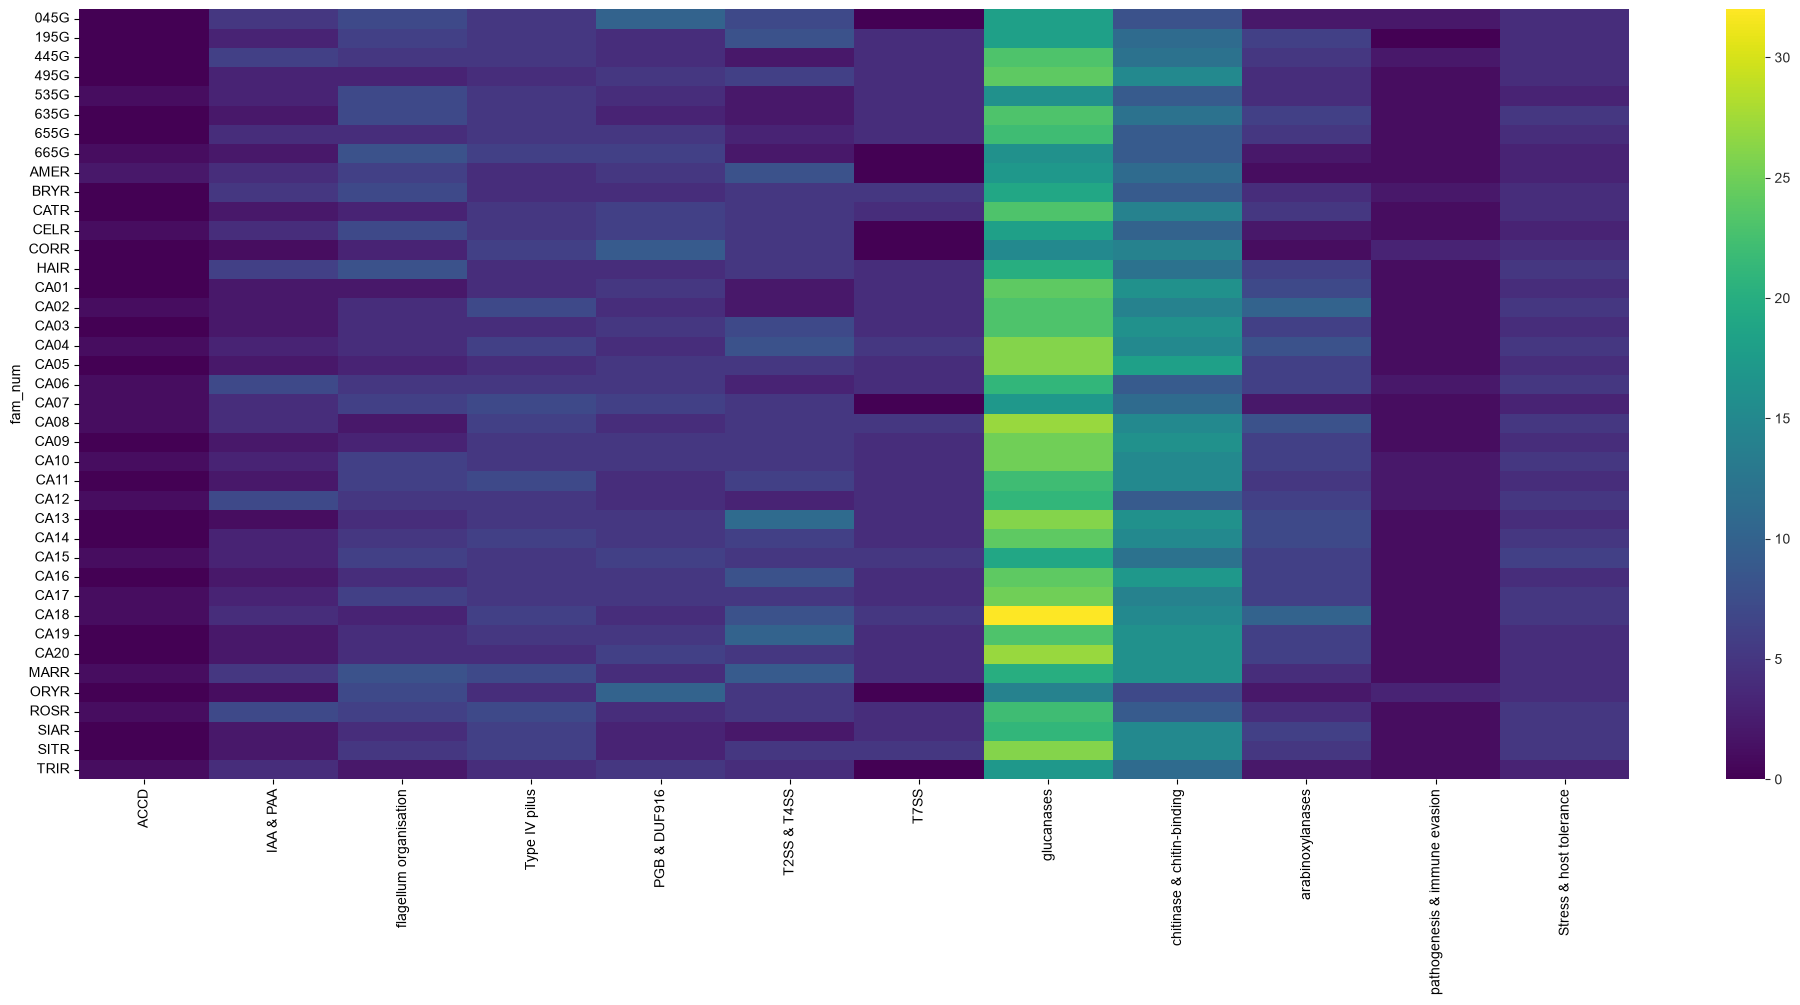

In [91]:
# Copied straight from BGC pivot table above, but here doesn;t allow nan values for some reason
fig1, ax1 = plt.subplots(figsize=(25,10))
sns.set_style("white")
sns.despine()
sns.heatmap(gene_fams_summary_df, cmap="viridis")
#plt.savefig("Gene_families_of_interest_summary_clean.png", bbox_inches='tight', dpi=600)


#### Supplementary Figures - CAZy

In [240]:
# Overall CAZyme summary
pers_CAZyme_summary_df = pers_gf_M_eggnog_df[pers_gf_M_eggnog_df['CAZy'] != "-"].copy()
pers_CAZyme_summary_df.loc[:,"pangenome"] = "persistent"
variable_CAZyme_summary_df = variable_gf_eggnog_df[variable_gf_eggnog_df['CAZy'] != "-"].copy()
variable_CAZyme_summary_df.loc[:,"pangenome"] = "variable"
CAZyme_summary_df = pd.concat([pers_CAZyme_summary_df, variable_CAZyme_summary_df])
CAZyme_counts = CAZyme_summary_df["CAZy"].value_counts().to_frame()
print(CAZyme_counts["count"].sum())
print(len(set(CAZyme_counts.index)))


535
54


In [241]:
# Make a summary dataframe for all CAZyme families
CAZyme_lists_all = CAZyme_summary_df.groupby('CAZy')['PanACoTA_gene_family'].apply(list).to_frame()

CAZyme_all_df = pd.DataFrame({
name: MICB_All_quali_df[[str(c) for c in cols]].sum(axis=1)
for name, cols in CAZyme_lists_all['PanACoTA_gene_family'].items()})

CAZyme_all_df["fam_num"] = MICB_All_quali_df["fam_num"].str.split('.').str[0]
CAZyme_all_df.set_index("fam_num", inplace=True)
CAZyme_all_df.index.name = 'strain'

CAZyme_all_df

,AA10,"AA10,CBM73","CBM42,GH54","CBM48,GH13",CBM50,"CBM6,GH43",CE1,CE10,GH105,GH13,...,GT20,GT26,GT28,GT35,GT39,GT4,GT81,GT87,GT9,PL8
strain,,,,,,,,,,,,,,,,,,,,,
045G,1,4,5,4,0,1,1,2,0,6,...,2,1,2,1,2,5,1,1,2,1
195G,1,5,2,4,0,1,0,1,0,6,...,2,1,4,1,1,5,1,1,1,1
445G,1,5,4,4,0,1,0,0,0,7,...,2,2,3,1,1,5,1,1,2,1
495G,2,7,4,4,0,0,0,0,0,6,...,2,1,4,1,2,6,1,1,2,1
535G,0,5,2,4,0,1,0,0,0,5,...,2,1,3,1,2,5,1,1,2,1
635G,1,4,4,4,0,1,0,1,0,10,...,2,2,4,1,1,9,1,1,2,0
655G,0,6,4,4,0,1,0,0,0,6,...,2,1,3,1,2,3,1,1,2,1
665G,0,6,4,4,0,1,1,0,0,5,...,2,2,3,1,1,3,1,1,2,1
AMER,1,6,3,4,0,0,1,1,0,5,...,2,1,4,1,2,5,1,1,2,1


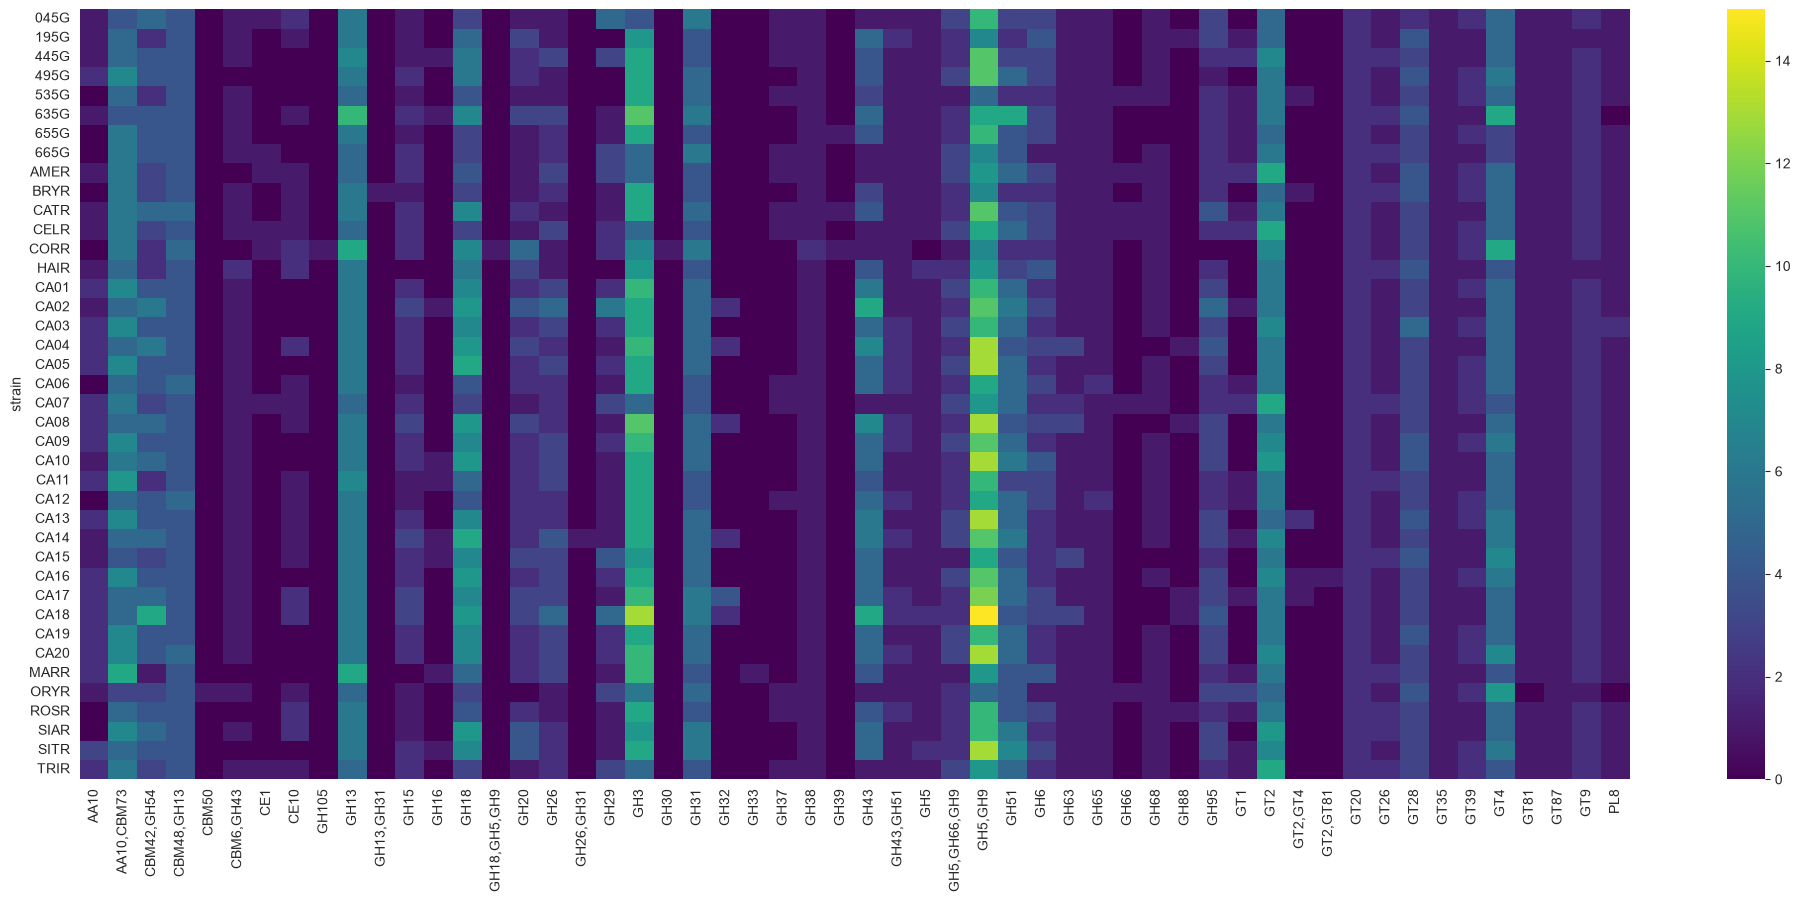

In [242]:
# Doesn't allow nan values for some reason
fig1, ax1 = plt.subplots(figsize=(25,10))
sns.set_style("white")
sns.despine()
sns.heatmap(CAZyme_all_df, cmap="viridis")
#plt.savefig("Gene_families_CAZyme_summary_clean.png", bbox_inches='tight', dpi=600)

#### Supplementary Figures - Secretion Systems, immune evasion, etc.

In [92]:
SS_immune_summary_list = ["2372", "22926", "41450", "44960", "46543", "48114", "3689", "1496", "11246", "14849", "17622", "20932", "22400", "27702", "30041", "50212", "12816", "13997", "17500", "1987", "17530", '477', '564', '14854', '27443', '48127', "2188", "19150", "24390", "3584", "35209", "4003", "4992", "9201", "13908", "27654", "50722", "15632", "19499", "19554", "49221", "1040", "36482", "2359", "4923", "8638", "27151", "49394", "10137", "15021", "25685", "32430", "35525", "40470", "4824", "30802", "33182", "33531", "40977", "41664", "43701", "50301", "10983", "13501", "22467", "28224", "33002", "45780", "5487", "613", "18985", "32584", "23095", "6062", "11953", "30067", "25540", "26478", "27570", "39355", "45767", "18199", "2150", "33319", "41053", "48981", "42679", "662", "24193"]
SS_immune_summary_int_list = [int(item) for item in SS_immune_summary_list]
SS_immune_summary_pers_df = pers_gf_M_eggnog_df[pers_gf_M_eggnog_df['PanACoTA_gene_family'].isin(SS_immune_summary_int_list)].copy()
SS_immune_summary_pers_df.loc[:,"pangenome"] = "persistent"
SS_immune_summary_var_df = variable_gf_eggnog_df[variable_gf_eggnog_df['PanACoTA_gene_family'].isin(SS_immune_summary_int_list)].copy()
SS_immune_summary_var_df.loc[:,"pangenome"] = "variable"
SS_immune_summary_df = pd.concat([SS_immune_summary_pers_df, SS_immune_summary_var_df])

#SS_immune_summary_df

In [93]:
# Only 5 unique "Preferred_name"
#print(set(SS_immune_summary_df["Preferred_name"]))
# Only 8 unique "EC"
#print(set(SS_immune_summary_df["EC"]))
# Only 10 unique "KEGG_ko"
#print(set(SS_immune_summary_df["KEGG_ko"]))
# Only 20 unique PFAMs
print(len(SS_immune_summary_df))
print(len(SS_immune_summary_df[SS_immune_summary_df["PFAMs"] == '-']))
print(set(SS_immune_summary_df["PFAMs"]))


89
4
{'PALP', 'Pentapeptide_3', 'CHAP,LysM', 'Sod_Ni', 'T2SSF', 'TIR_2,WD40', 'CN_hydrolase', 'T7SS_ESX1_EccB', 'Big_2,CHAP,CW_binding_1,Flg_new,GBS_Bsp-like,Glucosaminidase,Glyco_hydro_25,Peptidase_M23,RicinB_lectin_2', 'GPDPase_memb', 'Mo-co_dimer,Oxidored_molyb', 'WXG100', 'Catalase,Catalase-rel', 'Peptidase_C2,WXG100', 'YukD', 'He_PIG', '-', 'Aldedh', 'peroxidase', 'Catalase,Catalase-rel,DJ-1_PfpI', 'He_PIG,Kelch_6,Laminin_G_3,Malectin,NPCBM', 'T2SSE', 'Amino_oxidase'}


In [94]:
# Make a summary dataframe based on PFAM
SS_immune_lists_all = SS_immune_summary_df.groupby('PFAMs')['PanACoTA_gene_family'].apply(list).to_frame()

SS_immune_all_df = pd.DataFrame({
name: MICB_All_quali_df[[str(c) for c in cols]].sum(axis=1)
for name, cols in SS_immune_lists_all['PanACoTA_gene_family'].items()})

# Drop the "-" column and replace it with counts for the four gene families with tentative descriptions
SS_immune_all_df = pd.concat([SS_immune_all_df, MICB_All_quali_df[["1987", "12816", "13997", "17500"]]], axis=1)
SS_immune_all_df.rename(columns={"1987":"no_PFAM_tentative_Neu5Ac_conversion"}, inplace=True)
SS_immune_all_df["no_PFAM_tentative_LPG_biosynthesis"] = SS_immune_all_df[["12816", "13997", "17500"]].sum(axis=1)
SS_immune_all_df.drop(columns = ["-", "12816", "13997", "17500"], inplace=True)
# Reset and rename the index
SS_immune_all_df["fam_num"] = MICB_All_quali_df["fam_num"].str.split('.').str[0]
SS_immune_all_df.set_index("fam_num", inplace=True)
SS_immune_all_df.index.name = 'strain'

SS_immune_all_df

,Aldedh,Amino_oxidase,"Big_2,CHAP,CW_binding_1,Flg_new,GBS_Bsp-like,Glucosaminidase,Glyco_hydro_25,Peptidase_M23,RicinB_lectin_2","CHAP,LysM",CN_hydrolase,"Catalase,Catalase-rel","Catalase,Catalase-rel,DJ-1_PfpI",GPDPase_memb,He_PIG,"He_PIG,Kelch_6,Laminin_G_3,Malectin,NPCBM",...,Sod_Ni,T2SSE,T2SSF,T7SS_ESX1_EccB,"TIR_2,WD40",WXG100,YukD,peroxidase,no_PFAM_tentative_Neu5Ac_conversion,no_PFAM_tentative_LPG_biosynthesis
strain,,,,,,,,,,,,,,,,,,,,,
045G,0,3,0,0,2,1,0,1,0,0,...,1,1,6,0,0,0,0,1,0,1
195G,1,0,0,0,2,1,0,0,0,0,...,1,2,6,1,0,2,1,1,0,0
445G,2,2,0,0,2,2,0,1,0,0,...,1,0,2,1,0,2,1,1,0,1
495G,0,1,0,0,2,2,0,1,0,0,...,1,2,4,1,0,2,1,1,0,0
535G,1,0,0,0,2,1,0,1,0,0,...,1,0,2,1,0,2,1,1,0,0
635G,1,1,0,0,0,2,0,1,0,0,...,1,0,2,1,0,2,1,1,0,0
655G,1,1,0,0,2,2,0,1,0,0,...,1,0,2,1,0,2,1,1,0,0
665G,1,1,0,0,0,1,0,1,0,0,...,1,0,2,0,0,0,0,1,0,0
AMER,1,1,0,0,2,1,0,1,0,0,...,1,2,6,0,0,0,0,1,0,0


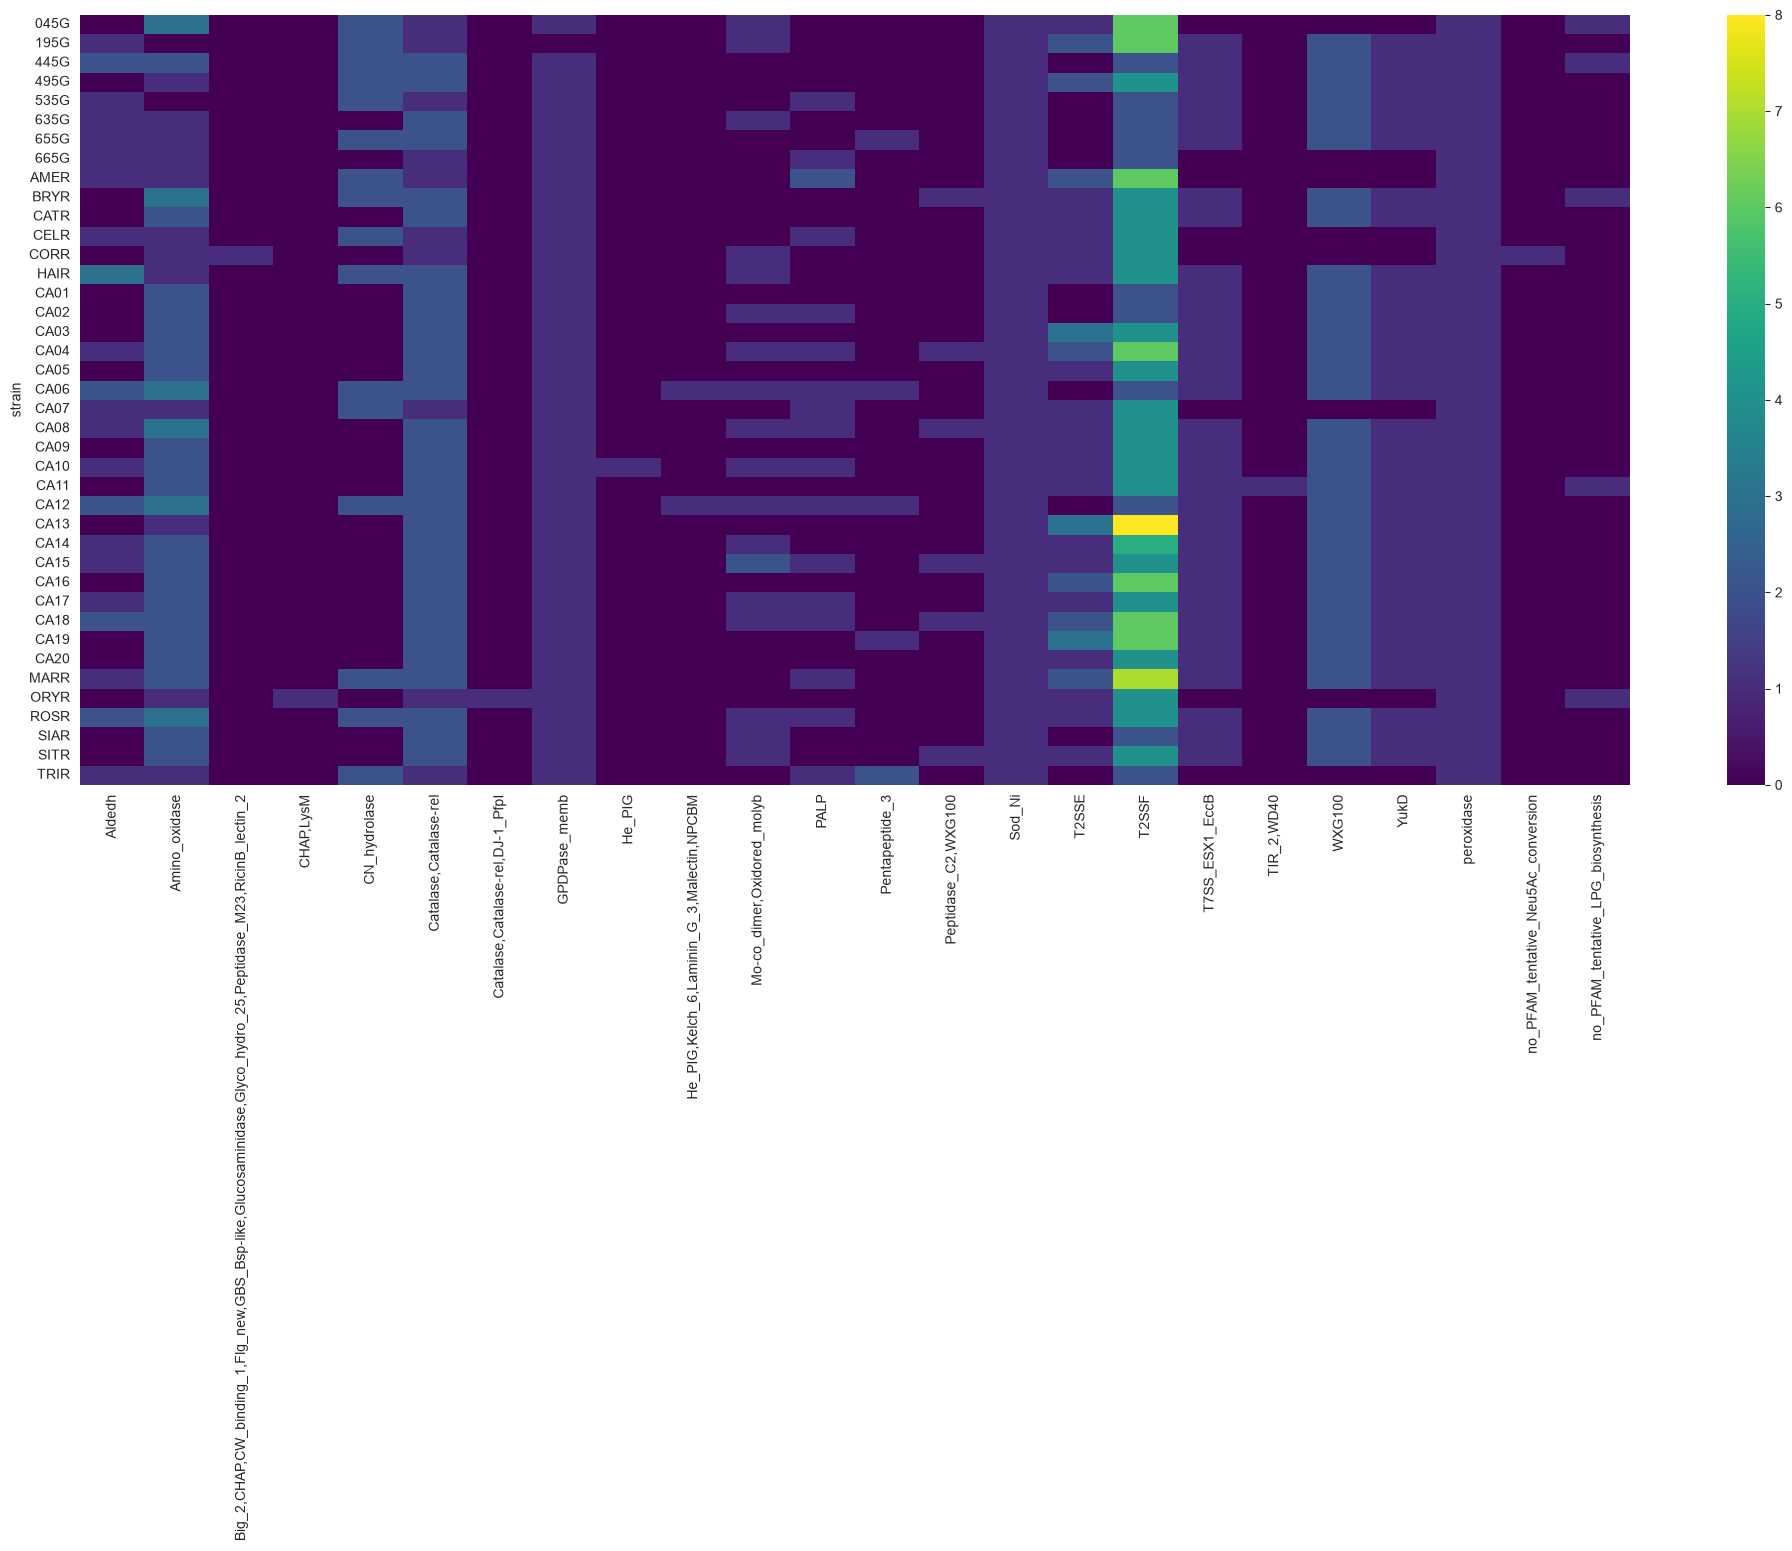

In [95]:
# Doesn't allow nan values for some reason
fig1, ax1 = plt.subplots(figsize=(25,10))
sns.set_style("white")
sns.despine()
sns.heatmap(SS_immune_all_df, cmap="viridis")
#plt.savefig("Gene_families_SS_immune_summary_clean.png", bbox_inches='tight', dpi=600)

## BGC Knownclusterblast summary

In [121]:
json_path = "..\\antiSMASH_json_files\\CORR.json"
with open(json_path, "r") as f:
    data = json.load(f)

In [122]:
# Could get this to return a dictionary of the max similarity of all regions
# Reference in Query (RiQ): How much of the reference MIBiG cluster is present inside your query region.
# Query in Reference (QiR): How much of your query region is covered by the reference MIBiG cluster
total_bgcs = 0
record_count = 0
total_sim = 0
for record in data.get("records", []):
    #print(record.get("id"))
    record_count += 1
    modules = record.get("modules", {})
    # Target the cluster comparison data rather than old clusterblast ranking arrays
    cluster_compare = modules.get("antismash.modules.cluster_compare", {})
    db_results = cluster_compare.get("db_results", {})
    mibig_data = db_results.get("MIBiG", {})
    #print(len(mibig_data))
    by_region = mibig_data.get("by_region", {}) # Mapped as {"1": [hits...], "2": [hits...]}
    region_count = 1
    for region in by_region:
        #print(str(record_count)+"."+str(region_count))
        first = by_region.get(region, {})
        RiQ = first.get('RegionToRegion_RiQ')
        #print(list(RiQ['scores_by_region'].values())[0])
        try:
            total_sim += list(RiQ['scores_by_region'].values())[0]
            region_count += 1
            total_bgcs += 1
        except IndexError:
            region_count += 1
            total_bgcs += 1
print(total_sim)
print(total_bgcs)
print(total_sim/total_bgcs)

13.651451844422992
22
0.6205205383828633


In [123]:
def json_to_avarage_MiBIG_RiQ_sim(json_path):
    with open(json_path, "r") as f:
        data = json.load(f)
        total_bgcs = 0
        record_count = 0
        total_sim = 0
        for record in data.get("records", []):
            record_count += 1
            modules = record.get("modules", {})
            cluster_compare = modules.get("antismash.modules.cluster_compare", {})
            db_results = cluster_compare.get("db_results", {})
            mibig_data = db_results.get("MIBiG", {})
            by_region = mibig_data.get("by_region", {}) # Mapped as {"1": [hits...], "2": [hits...]}
            region_count = 1
            for region in by_region:
                first = by_region.get(region, {})
                RiQ = first.get('RegionToRegion_RiQ')
                try:
                    total_sim += list(RiQ['scores_by_region'].values())[0]
                    region_count += 1
                    total_bgcs += 1
                except IndexError:
                    region_count += 1
                    total_bgcs += 1

    return(total_sim/total_bgcs)

In [125]:
json_to_avarage_MiBIG_RiQ_sim("..\\antiSMASH_json_files\\CORR.json")

0.6205205383828633

In [104]:
directory_path = "..\\antiSMASH_json_files\\"
for filename in os.listdir(directory_path):
    print(filename)
    # Filter for JSON files
    if filename.endswith(".json"):
        file_path = os.path.join(directory_path, filename)
        print(json_to_avarage_MiBIG_RiQ_sim(file_path))


045G.json
0.5997274031563856
195G.json
0.6574538700317708
445G.json
0.6339896350127802
495G.json
0.6452275291378056
535G.json
0.6808574449225231
635G.json
0.658082030389906
655G.json
0.6677742482583788
665G.json
0.6587308020185287
AMER.json
0.6190156677672943
BRYR.json
0.671935981995005
CA01.json
0.6562936939585025
CA02.json
0.6614670697313985
CA03.json
0.6624966127329375
CA04.json
0.6851820654047938
CA05.json
0.6562229253209639
CA06.json
0.6634340023664711
CA07.json
0.6570486489644991
CA08.json
0.6633121076507613
CA09.json
0.6566731482422813
CA10.json
0.6685112162550786
CA11.json
0.6606301919018223
CA12.json
0.6701598738810226
CA13.json
0.6522396583215303
CA14.json
0.6619859936551136
CA15.json
0.6849780709375496
CA16.json
0.6515889925709225
CA17.json
0.669309760193007
CA18.json
0.6642935549819546
CA19.json
0.6561785213938516
CA20.json
0.6560227459308186
CATR.json
0.6088135921750715
CELR.json
0.6446710839675968
CORR.json
0.6205205383828633
HAIR.json
0.6660878628752662
MARR.json
0.67330

# BGC summary figure from lsaBG-Pan Consolidated worksheets BGC summary

In [5]:
lsabgc_sum_df = pd.read_csv("Clean_BGC_summary.csv")
lsabgc_sum_df.head(2)

,sample,population,method,bgc_id,bgc_type,gcf_id,scaffold,start,end,bgc_length,dist_to_edge
0,535G,Clade_1,antismash,535G_NZ_JABBWV010000001.1.region001,T1PKS | other,GCF_24,NZ_JABBWV010000001.1,132342,208244,75903,132342
1,535G,Clade_1,antismash,535G_NZ_JABBWV010000001.1.region003,T1PKS,GCF_39,NZ_JABBWV010000001.1,966763,1039634,72872,181370


In [3]:
# Count the number of complete and fragmented BGCs as determined by distance to edge of contig
lsabgc_sum_df.groupby("sample")["dist_to_edge"].count()

sample
045G    39
195G    27
445G    28
495G    33
535G    21
635G    25
655G    27
665G    25
AMER    42
BRYR    21
CA01    27
CA02    24
CA03    28
CA04    22
CA05    27
CA06    23
CA07    27
CA08    22
CA09    28
CA10    28
CA11    24
CA12    24
CA13    27
CA14    24
CA15    28
CA16    29
CA17    24
CA18    25
CA19    27
CA20    28
CATR    26
CELR    34
CORR    22
HAIR    23
MARR    23
ORYR    33
ROSR    21
SIAR    33
SITR    32
TRIR    35
Name: dist_to_edge, dtype: int64

In [4]:
# Count the number of complete and fragmented BGCs as determined by distance to edge of contig equal to 1 or less
lsabgc_sum_df[lsabgc_sum_df["dist_to_edge"] <= 1].groupby("sample")["dist_to_edge"].count().reset_index(name='Frag_Count')


,sample,Frag_Count
0,045G,22
1,495G,14
2,535G,1
3,635G,5
4,655G,5
5,AMER,21
6,CATR,6
7,CELR,8
8,CORR,11
9,HAIR,9


In [5]:
print(len(lsabgc_sum_df["bgc_type"].unique()))
lsabgc_type_df = lsabgc_sum_df.groupby("sample")["bgc_type"].value_counts().reset_index()
lsabgc_type_pivot_df = lsabgc_type_df.pivot(index="sample", columns="bgc_type", values="count")
lsabgc_type_pivot_df

78


bgc_type,LAP,LAP | RRE-containing | thiopeptide,LAP | T3PKS,LAP | thiopeptide,NAPAA,NAPAA | NRPS,NI-siderophore,NI-siderophore | other,NRP-metallophore | NRPS,NRP-metallophore | NRPS | T1PKS,...,other,phenazine,phosphonate,redox-cofactor,terpene,terpene | thioamitides | thiopeptide,thioamide-NRP,thioamitides,thioamitides | thiopeptide,thiopeptide
sample,,,,,,,,,,,,,,,,,,,,,
045G,1.0,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,NaN,...,NaN,NaN,1.0,NaN,4.0,1.0,NaN,NaN,NaN,NaN
195G,1.0,NaN,NaN,NaN,1.0,NaN,2.0,NaN,NaN,NaN,...,NaN,1.0,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN
445G,1.0,NaN,NaN,NaN,1.0,NaN,2.0,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN
495G,NaN,NaN,NaN,1.0,NaN,NaN,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,1.0,1.0
535G,1.0,1.0,NaN,NaN,1.0,NaN,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN
635G,NaN,NaN,NaN,1.0,NaN,NaN,2.0,NaN,1.0,NaN,...,NaN,2.0,NaN,NaN,5.0,NaN,NaN,NaN,1.0,NaN
655G,NaN,NaN,1.0,1.0,NaN,NaN,2.0,NaN,NaN,NaN,...,NaN,1.0,NaN,NaN,5.0,NaN,NaN,NaN,1.0,NaN
665G,NaN,NaN,NaN,NaN,1.0,NaN,2.0,NaN,NaN,NaN,...,NaN,1.0,NaN,1.0,5.0,NaN,NaN,NaN,1.0,NaN
AMER,NaN,NaN,NaN,NaN,1.0,NaN,2.0,NaN,NaN,NaN,...,NaN,1.0,NaN,1.0,5.0,NaN,NaN,1.0,1.0,NaN


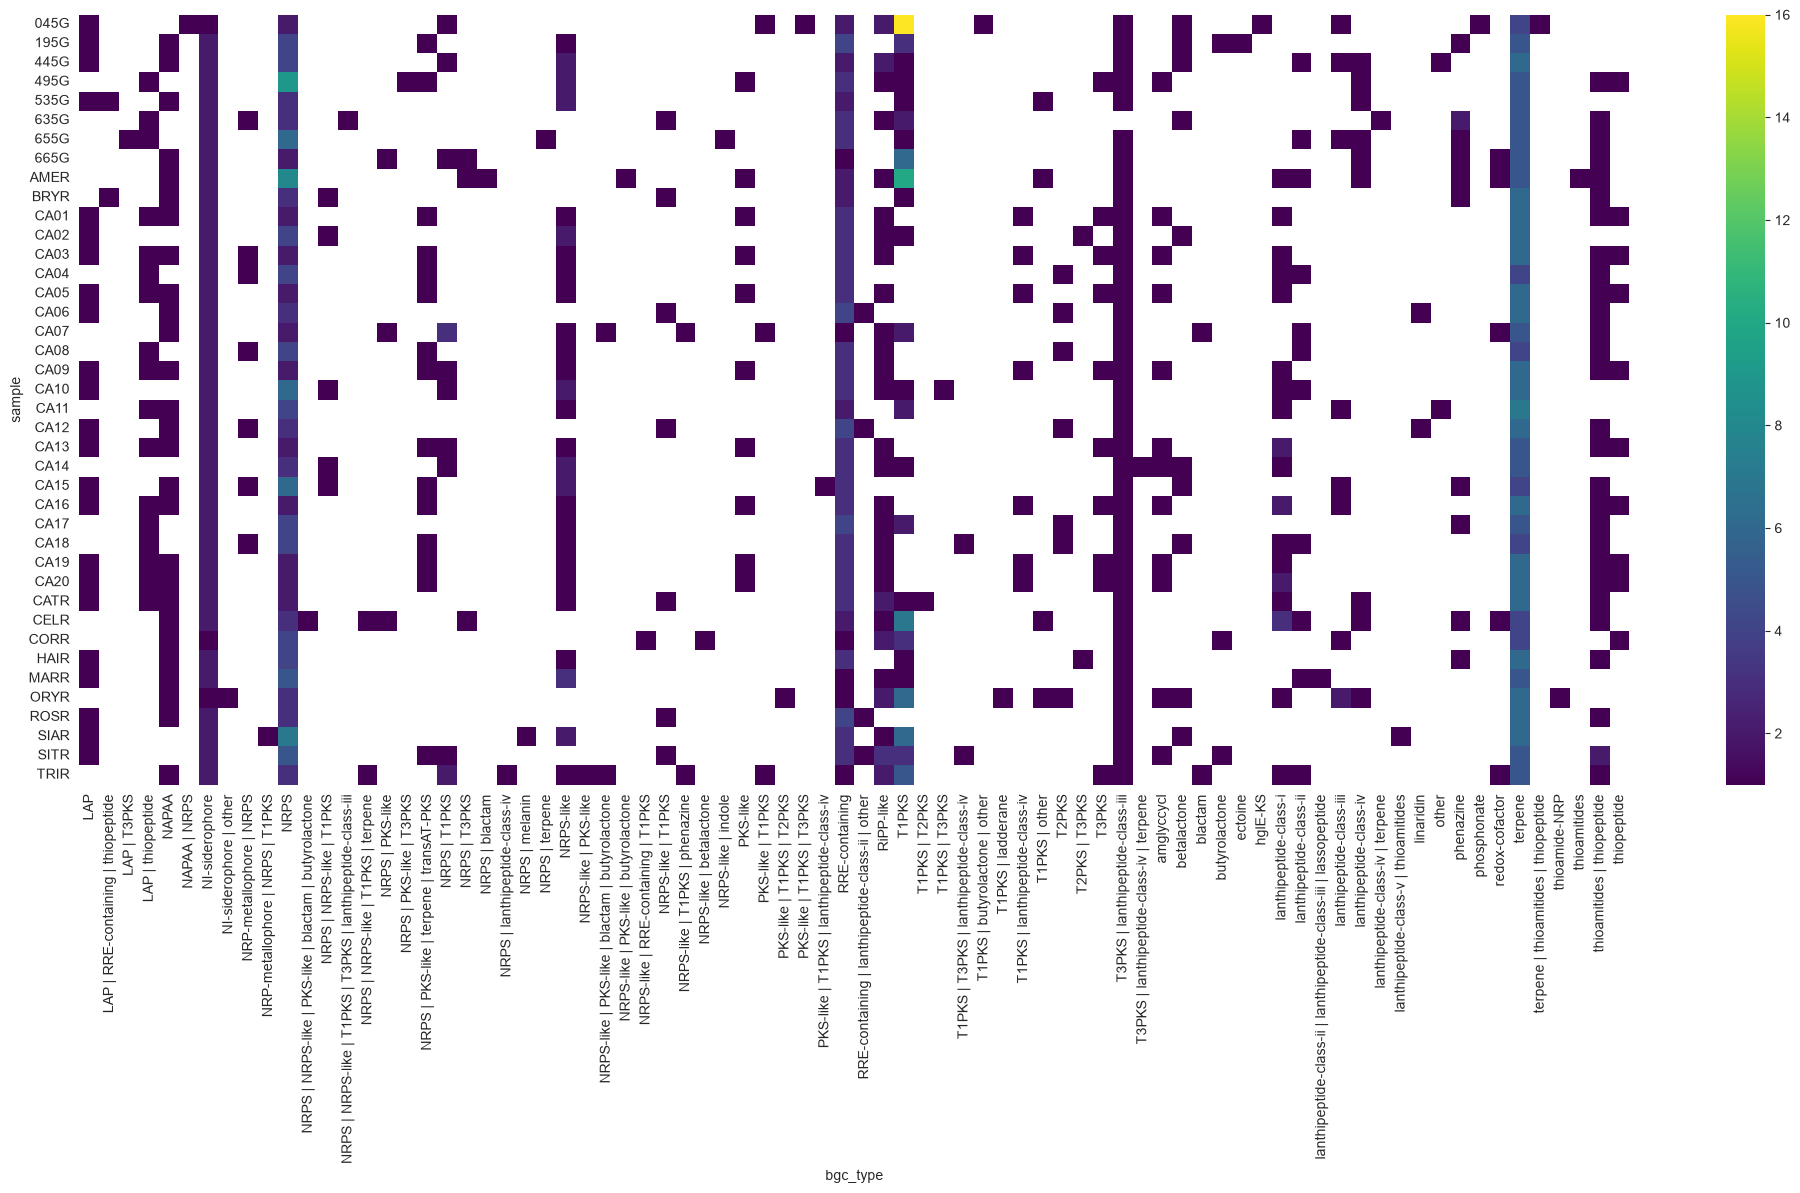

In [8]:
fig0, ax0 = plt.subplots(figsize=(25,10))
sns.set_style("white")
sns.despine()
sns.heatmap(lsabgc_type_pivot_df, cmap="viridis")
plt.savefig("BGC_type_summary_clean.png", facecolor="white", bbox_inches='tight', dpi=1200)


In [7]:
zero_counts = lsabgc_sum_df.groupby('sample')['dist_to_edge'].agg(lambda x: x.eq(0).sum()).reset_index()
BGC_counts = lsabgc_sum_df.groupby('sample').size().reset_index()
lsabgc_count_df = pd.merge(BGC_counts, zero_counts, on="sample")
lsabgc_count_df["# complete BGC"] = lsabgc_count_df[0] - lsabgc_count_df["dist_to_edge"]
lsabgc_count_df.rename(columns={"dist_to_edge": "# fragmented BGCs"}, inplace=True)
lsabgc_count_df.drop(columns=[0], inplace=True)
lsabgc_count_df

,sample,# fragmented BGCs,# complete BGC
0,045G,19,20
1,195G,0,27
2,445G,0,28
3,495G,11,22
4,535G,0,21
5,635G,3,22
6,655G,2,25
7,665G,0,25
8,AMER,14,28
9,BRYR,0,21


### Anlysis of GCFs by isolation source

In [3]:
iso_df = pd.read_csv("BGC_isolation.source.clean.txt")

In [6]:
iso_lsabgc_sum_df = pd.merge(lsabgc_sum_df,iso_df, on='sample', how="outer")

In [7]:
print(len(lsabgc_sum_df))
print(len(iso_lsabgc_sum_df))
iso_lsabgc_sum_df.head(3)

1086
1086


,sample,population,method,bgc_id,bgc_type,gcf_id,scaffold,start,end,bgc_length,dist_to_edge,isolation_source
0,045G,Clade_2,antismash,045G_NZ_JBEZDW010000030.1.region002,NAPAA | NRPS,GCF_69,NZ_JBEZDW010000030.1,51726,114779,63054,1,Unknown
1,045G,Clade_2,antismash,045G_NZ_JBEZDW010000045.1.region001,PKS-like | T1PKS | T3PKS,GCF_88,NZ_JBEZDW010000045.1,11153,65256,54104,1,Unknown
2,045G,Clade_2,antismash,045G_NZ_JBEZDW010000008.1.region002,NRPS,GCF_6,NZ_JBEZDW010000008.1,125529,177545,52017,98793,Unknown


In [8]:
GCF_iso_list_df = iso_lsabgc_sum_df.groupby('gcf_id')['isolation_source'].unique().transform(list).reset_index()
plant_only_GCF_list = GCF_iso_list_df[GCF_iso_list_df['isolation_source'].apply(lambda x: x == ['Plant'])]['gcf_id'].tolist()
print(len(plant_only_GCF_list))
plant_only_lsabgc = iso_lsabgc_sum_df[iso_lsabgc_sum_df['gcf_id'].isin(plant_only_GCF_list) == True]
plant_only_lsabgc.sort_values('gcf_id')

33


,sample,population,method,bgc_id,bgc_type,gcf_id,scaffold,start,end,bgc_length,dist_to_edge,isolation_source
941,ORYR,Clade_4,antismash,ORYR_NZ_JAFCNB010000023.1.region001,NRPS,GCF_100,NZ_JAFCNB010000023.1,26300,69149,42850,26300,Plant
1062,TRIR,Clade_5,antismash,TRIR_NZ_VANP01000005.1.region001,T3PKS,GCF_102,NZ_VANP01000005.1,108692,148455,39764,108692,Plant
943,ORYR,Clade_4,antismash,ORYR_NZ_JAFCNB010000023.1.region002,NI-siderophore | other,GCF_104,NZ_JAFCNB010000023.1,73518,110992,37475,1,Plant
945,ORYR,Clade_4,antismash,ORYR_NZ_JAFCNB010000014.1.region001,NAPAA,GCF_106,NZ_JAFCNB010000014.1,22841,56704,33864,22841,Plant
734,CA18,Clade_6,antismash,CA18_ctg.s1pl0000000.region021,betalactone,GCF_111,ctg.s1pl0000000,7768248,7799042,30795,730346,Plant
658,CA15,Clade_6,antismash,CA15_ptg000001l.region006,betalactone,GCF_115,ptg000001l,1886532,1913748,27217,1886532,Plant
948,ORYR,Clade_4,antismash,ORYR_NZ_JAFCNB010000008.1.region001,betalactone,GCF_120,NZ_JAFCNB010000008.1,157641,180608,22968,129239,Plant
949,ORYR,Clade_4,antismash,ORYR_NZ_JAFCNB010000011.1.region001,lanthipeptide-class-iv,GCF_121,NZ_JAFCNB010000011.1,147528,170176,22649,60966,Plant
686,CA16,Clade_6,antismash,CA16_ptg000001c.region013,lanthipeptide-class-iii,GCF_123,ptg000001c,5444770,5467322,22553,3770853,Plant
950,ORYR,Clade_4,antismash,ORYR_NZ_JAFCNB010000031.1.region001,lanthipeptide-class-iii,GCF_125,NZ_JAFCNB010000031.1,2325,24841,22517,2325,Plant


In [9]:
iso_lsabgc_sum_df.to_csv("Clean_BGC_GCF_isolation_source_summary.csv")